In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False


In [12]:
df = pd.read_csv('./data/i.csv', encoding='euc-kr')

In [10]:
counts = df['계선장소'].value_counts()
print(counts)

계선장소
MBF    1859
MBY     893
MBR     248
MB1      14
MB6       8
WAN       7
MBS       4
WAS       4
Name: count, dtype: int64


전체 입항 횟수: 1518

계선장소별 입항 횟수 및 비중
              계선장소  입항횟수  입항비중(%)
      북항크루즈터미널 1선석   522    34.39
          영도크루즈터미널   446    29.38
      국제여객터미널 14선석   276    18.18
      북항크루즈터미널 2선석   128     8.43
감만부두 3선석(신선대감만터미널)   121     7.97
          1부두 14선석     7     0.46
        자성대부두 64선석     4     0.26
         남외항 N-4박지     4     0.26
         남외항 N-5박지     2     0.13
감만부두 2선석(신선대감만터미널)     2     0.13
         신선대부두 5선석     1     0.07
         신선대부두 2선석     1     0.07
감만부두 4선석(신선대감만터미널)     1     0.07
        수영박지(집단박지)     1     0.07
      국제여객터미널 10선석     1     0.07
      국제여객터미널 13선석     1     0.07


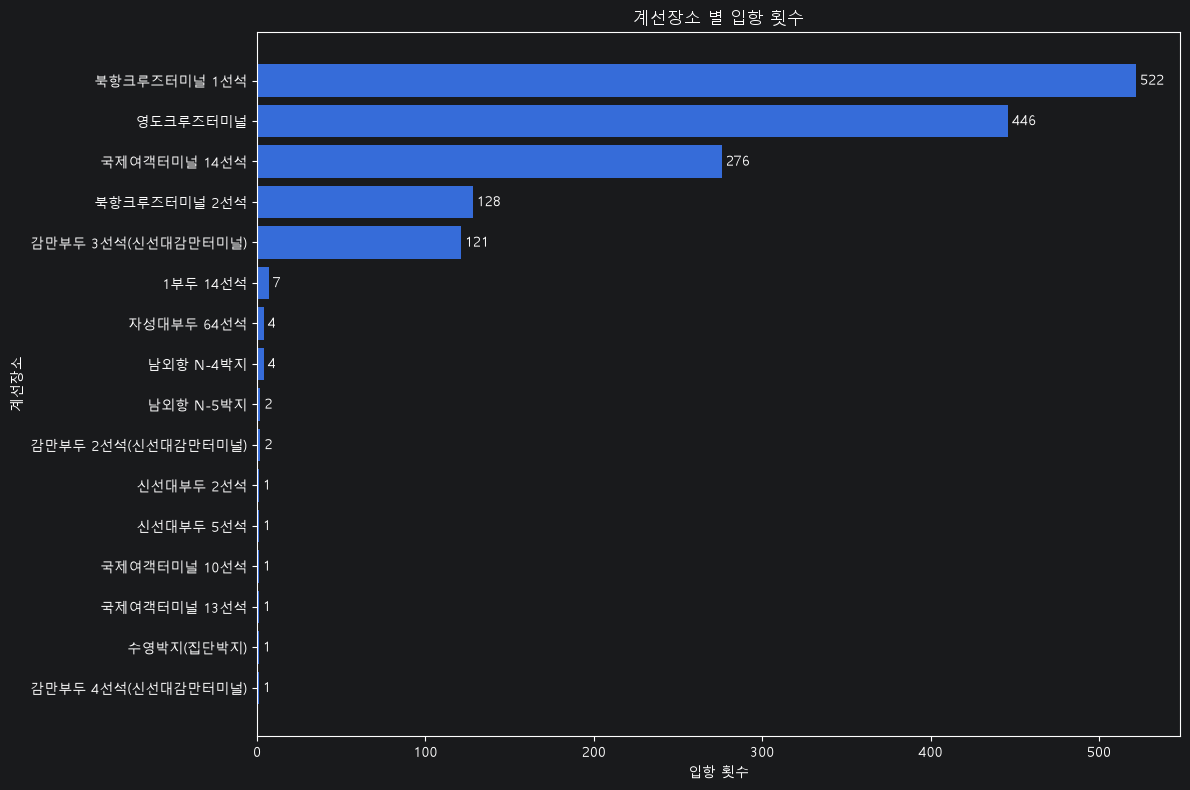

In [33]:
# 1. 계선장소별 크루즈선 입항 횟수

# 2. 입항 기록만 추출
df["입출"] = df["입출"].astype(str).str.strip()

arrival = df[df["입출"] == "입항"].copy()

# 3. 계선장소별 입항 횟수 집계
berth_col = "계선장소.2"

berth_counts = (
    arrival[berth_col]
    .fillna("미상")
    .value_counts()
    .rename_axis("계선장소")
    .reset_index(name="입항횟수")
)

# 4. 전체 입항 대비 비중 계산
total_arrivals = berth_counts["입항횟수"].sum()

berth_counts["입항비중(%)"] = (
    berth_counts["입항횟수"] / total_arrivals * 100
).round(2)

# 5. 결과 출력
print("전체 입항 횟수:", total_arrivals)
print("\n계선장소별 입항 횟수 및 비중")
print(berth_counts.to_string(index=False))

# 6. 막대그래프
plot_df = berth_counts.sort_values("입항횟수")

plt.figure(figsize=(12, 8))
bars = plt.barh(
    plot_df["계선장소"],
    plot_df["입항횟수"]
)

plt.bar_label(bars, fmt="%.0f", padding=3)
plt.title("계선장소 별 입항 횟수")
plt.xlabel("입항 횟수")
plt.ylabel("계선장소")
plt.tight_layout()
plt.show()


# 7. 결과 CSV 저장
berth_counts.to_csv(
    "계선장소별_입항횟수.csv",
    index=False,
    encoding="utf-8-sig"
)


전체 승객수: 2,772,719
              계선장소      총승객수       평균승객수  승객수_기록건수  입항횟수  승객비중(%)
          영도크루즈터미널 1060842.0 2378.569507       446   446    38.26
      북항크루즈터미널 1선석  911376.0 1745.931034       522   522    32.87
감만부두 3선석(신선대감만터미널)  440160.0 3637.685950       121   121    15.87
      국제여객터미널 14선석  289082.0 1047.398551       276   276    10.43
      북항크루즈터미널 2선석   45844.0  358.156250       128   128     1.65
        자성대부두 64선석    7484.0 1871.000000         4     4     0.27
         신선대부두 5선석    3475.0 3475.000000         1     1     0.13
감만부두 4선석(신선대감만터미널)    3032.0 3032.000000         1     1     0.11
          1부두 14선석    2897.0  413.857143         7     7     0.10
         신선대부두 2선석    2329.0 2329.000000         1     1     0.08
      국제여객터미널 13선석    1881.0 1881.000000         1     1     0.07
      국제여객터미널 10선석    1372.0 1372.000000         1     1     0.05
         남외항 N-5박지    1325.0  662.500000         2     2     0.05
감만부두 2선석(신선대감만터미널)     780.0  390.000000         2     2  

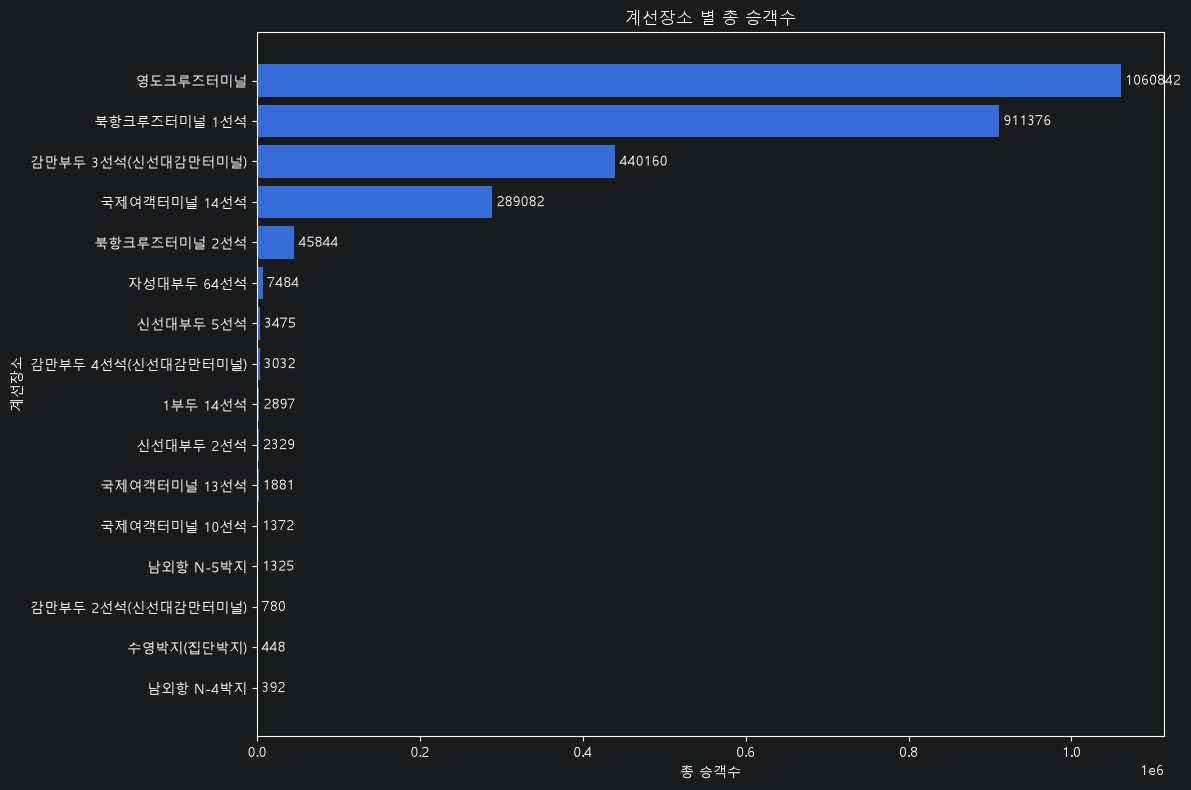

In [34]:
# 2. 계선장소별 승객수 현황

# 1. 승객 열을 숫자형으로 변환
arrival["승객"] = pd.to_numeric(
    arrival["승객"], errors="coerce"
)

# 2. 계선장소별 승객수 집계
passenger_stats = (
    arrival.groupby("계선장소.2", dropna=False)
    .agg(
        총승객수=("승객", "sum"),
        평균승객수=("승객", "mean"),
        승객수_기록건수=("승객", "count"),
        입항횟수=("승객", "size")
    )
    .reset_index()
    .rename(columns={"계선장소.2": "계선장소"})
)

# 3. 전체 승객 대비 장소별 비중
total_passengers = passenger_stats["총승객수"].sum()

passenger_stats["승객비중(%)"] = (
    passenger_stats["총승객수"] / total_passengers * 100
).round(2)

# 4. 승객수가 많은 순서로 정렬
passenger_stats = passenger_stats.sort_values(
    "총승객수", ascending=False
)

# 5. 결과 출력
print("전체 승객수:", f"{total_passengers:,.0f}")
print(passenger_stats.to_string(index=False))

# 6. 총승객수 막대그래프
plot_df = passenger_stats.sort_values("총승객수")

plt.figure(figsize=(12, 8))
bars = plt.barh(
    plot_df["계선장소"].fillna("미상"),
    plot_df["총승객수"]
)

plt.bar_label(bars, fmt="%.0f", padding=3)
plt.title("계선장소 별 총 승객수")
plt.xlabel("총 승객수")
plt.ylabel("계선장소")
plt.tight_layout()
plt.show()

# 7. 결과 저장
passenger_stats.to_csv(
    "계선장소별_승객수.csv",
    index=False,
    encoding="utf-8-sig"
)


In [19]:
# 2-1. 계선 장소 중 결측치 있는 장소 발견

# 승객수를 숫자형으로 변환
arrival["승객"] = pd.to_numeric(
    arrival["승객"], errors="coerce"
)

# 1. 승객수가 누락된 입항 기록 확인
missing_passengers = arrival[arrival["승객"].isna()]

print("승객수 결측 기록:")
print(
    missing_passengers[
        ["선명", "호출부호", "입항일시", "계선장소.2", "승객"]
    ].to_string(index=False)
)

# 2. 계선장소별 결측 및 0명 기록 확인
check = (
    arrival.groupby("계선장소.2", dropna=False)
    .agg(
        입항횟수=("승객", "size"),
        승객수_결측=("승객", lambda s: s.isna().sum()),
        승객수_0명=("승객", lambda s: s.eq(0).sum()),
        승객수_기록건수=("승객", "count"),
        총승객수=("승객", "sum")
    )
    .reset_index()
)

print("\n계선장소별 데이터 점검:")
print(
    check[check["승객수_결측"] > 0]
    .to_string(index=False)
)

# 3. 전체 검증
print("\n전체 검증")
print("입항 횟수:", len(arrival))
print("결측 기록:", arrival["승객"].isna().sum())
print("0명 기록:", arrival["승객"].eq(0).sum())
print("승객수 기록 건수:", arrival["승객"].count())
print("총승객수:", arrival["승객"].sum())


승객수 결측 기록:
           선명   호출부호             입항일시    계선장소.2  승객
EASTERN VENUS 3E7469 2025-03-06 14:00 남외항 N-4박지 NaN
EASTERN VENUS 3E7469 2025-12-13 10:00 남외항 N-4박지 NaN

계선장소별 데이터 점검:
   계선장소.2  입항횟수  승객수_결측  승객수_0명  승객수_기록건수  총승객수
남외항 N-4박지     4       2       0         2 392.0

전체 검증
입항 횟수: 1518
결측 기록: 2
0명 기록: 0
승객수 기록 건수: 1516
총승객수: 2772719.0


분석 대상 계선장소:
- 북항크루즈터미널 1선석
- 영도크루즈터미널
- 국제여객터미널 14선석
- 북항크루즈터미널 2선석
- 감만부두 3선석(신선대감만터미널)

연도별 입항 횟수:
계선장소.2  감만부두 3선석(신선대감만터미널)  국제여객터미널 14선석  북항크루즈터미널 1선석  북항크루즈터미널 2선석  영도크루즈터미널
연도                                                                            
2013                     0             0             0             0        92
2014                    12             0             0             0        90
2015                    15             1             0             0        48
2016                    67            57             1             1        79
2017                    26            40            15             6         0
2018                     1            19            47            12         0
2019                     0            23            59            21         3
2023                     0             0            72            13        19
2024                     0            12            81            14         7
2025                     0    

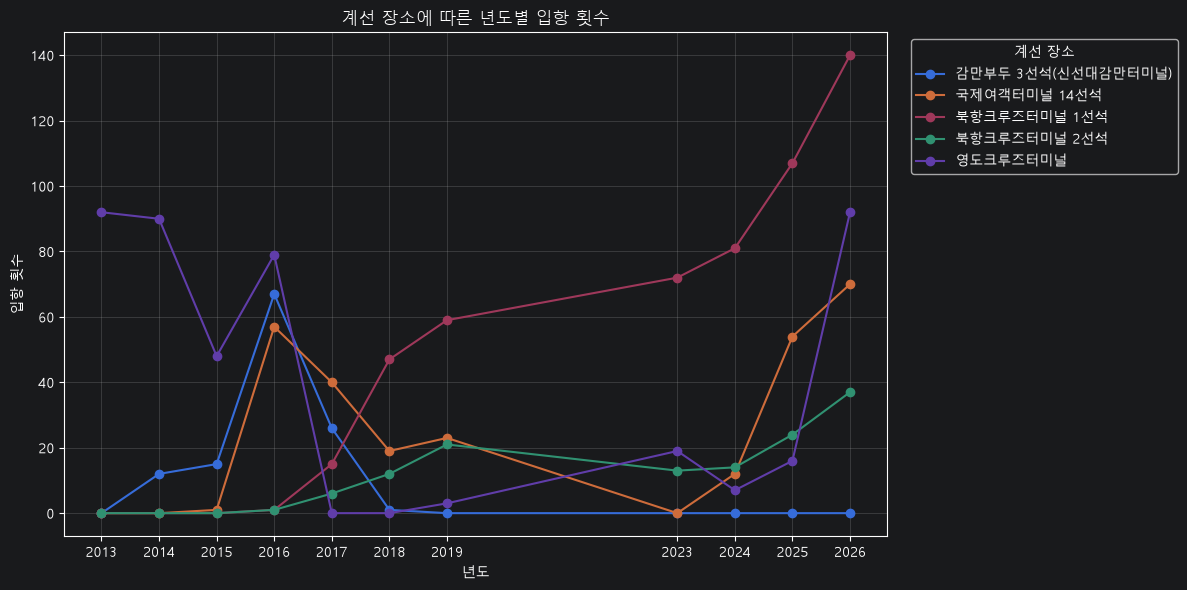

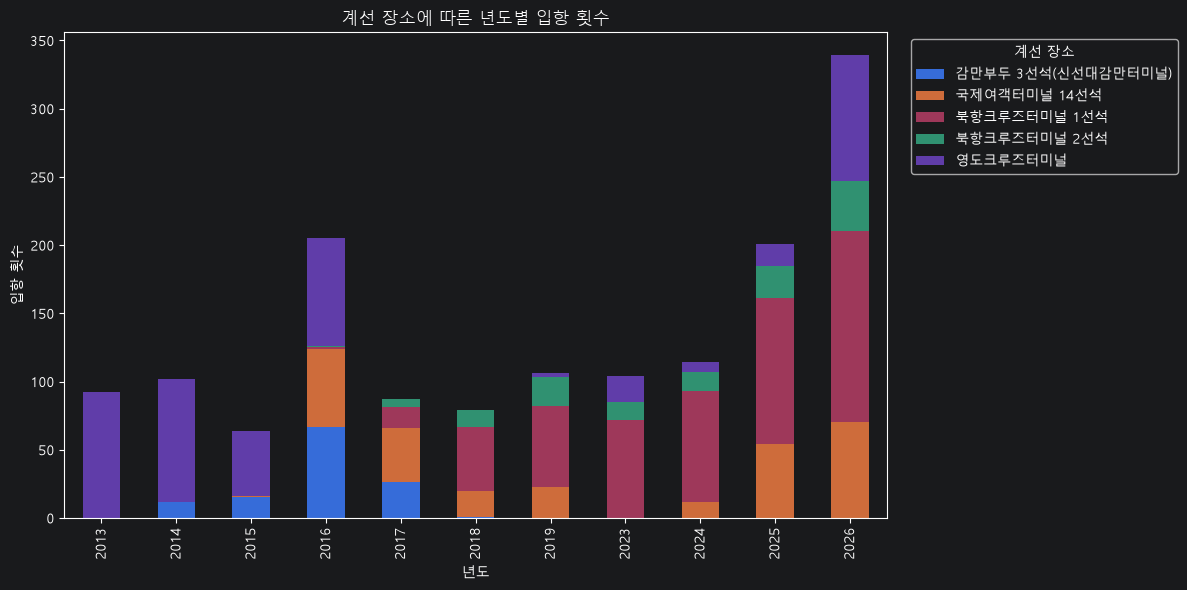


전년 대비 입항 횟수 증감률(%):
계선장소.2  감만부두 3선석(신선대감만터미널)  국제여객터미널 14선석  북항크루즈터미널 1선석  북항크루즈터미널 2선석  영도크루즈터미널
연도                                                                            
2013                   NaN           NaN           NaN           NaN       NaN
2014                   inf           NaN           NaN           NaN     -2.17
2015                 25.00           inf           NaN           NaN    -46.67
2016                346.67       5600.00           inf           inf     64.58
2017                -61.19        -29.82       1400.00        500.00   -100.00
2018                -96.15        -52.50        213.33        100.00       NaN
2019               -100.00         21.05         25.53         75.00       inf
2023                   NaN       -100.00         22.03        -38.10    533.33
2024                   NaN           inf         12.50          7.69    -63.16
2025                   NaN        350.00         32.10         71.43    128.57
2026                   NaN     

In [35]:
# 연도별 입항 횟수 및 입항 집중 경향

# 1. 입항일시를 날짜형으로 변환
arrival["입항일시"] = pd.to_datetime(
    arrival["입항일시"], errors="coerce"
)

# 2. 연도 변수 생성
arrival["연도"] = arrival["입항일시"].dt.year

# 3. 상위 5개 계선장소 선정
top5_berths = (
    arrival["계선장소.2"]
    .value_counts()
    .head(5)
    .index
    .tolist()
)

print("분석 대상 계선장소:")
for berth in top5_berths:
    print("-", berth)

# 4. 상위 5개 장소의 연도별 입항 횟수 집계
yearly_counts = (
    arrival[arrival["계선장소.2"].isin(top5_berths)]
    .groupby(["연도", "계선장소.2"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

print("\n연도별 입항 횟수:")
print(yearly_counts)

# 5. 연도별 입항 횟수 선그래프
ax = yearly_counts.plot(
    kind="line",
    marker="o",
    figsize=(12, 6)
)

ax.set_title("계선 장소에 따른 년도별 입항 횟수")
ax.set_xlabel("년도")
ax.set_ylabel("입항 횟수")
ax.set_xticks(yearly_counts.index)
ax.grid(True, alpha=0.3)

plt.legend(
    title="계선 장소",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

# 6. 연도별 장소 구성 누적 막대그래프
yearly_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("계선 장소에 따른 년도별 입항 횟수")
plt.xlabel("년도")
plt.ylabel("입항 횟수")
plt.legend(
    title="계선 장소",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

# 7. 전년 대비 증감률 계산
yearly_change = yearly_counts.pct_change() * 100

print("\n전년 대비 입항 횟수 증감률(%):")
print(yearly_change.round(2))

# 8. 결과 CSV 저장
yearly_counts.to_csv(
    "년도별_계선장소별_입항횟수.csv",
    encoding="utf-8-sig"
)

yearly_change.round(2).to_csv(
    "년도별_계선장소별_입항증감률.csv",
    encoding="utf-8-sig"
)


연도별 전체 입항 횟수
연도
2013    106
2014    104
2015     64
2016    205
2017     89
2018     80
2019    107
2023    105
2024    114
2025    205
2026    339
dtype: int64

연도별 계선장소 입항 비중(%)
계선장소.2  1부두 14선석  감만부두 2선석(신선대감만터미널)  감만부두 3선석(신선대감만터미널)  감만부두 4선석(신선대감만터미널)  국제여객터미널 10선석  국제여객터미널 13선석  국제여객터미널 14선석  남외항 N-4박지  남외항 N-5박지  북항크루즈터미널 1선석  북항크루즈터미널 2선석  수영박지(집단박지)  신선대부두 2선석  신선대부두 5선석  영도크루즈터미널  자성대부두 64선석
연도                                                                                                                                                                                                                              
2013         6.6                0.00                0.00                0.00          0.00          0.00          0.00       0.00       0.94          0.00          0.00        0.00       0.94       0.94     86.79        3.77
2014         0.0                0.00               11.54                0.96          0.00          0.00          0.00       0.96       0.00     

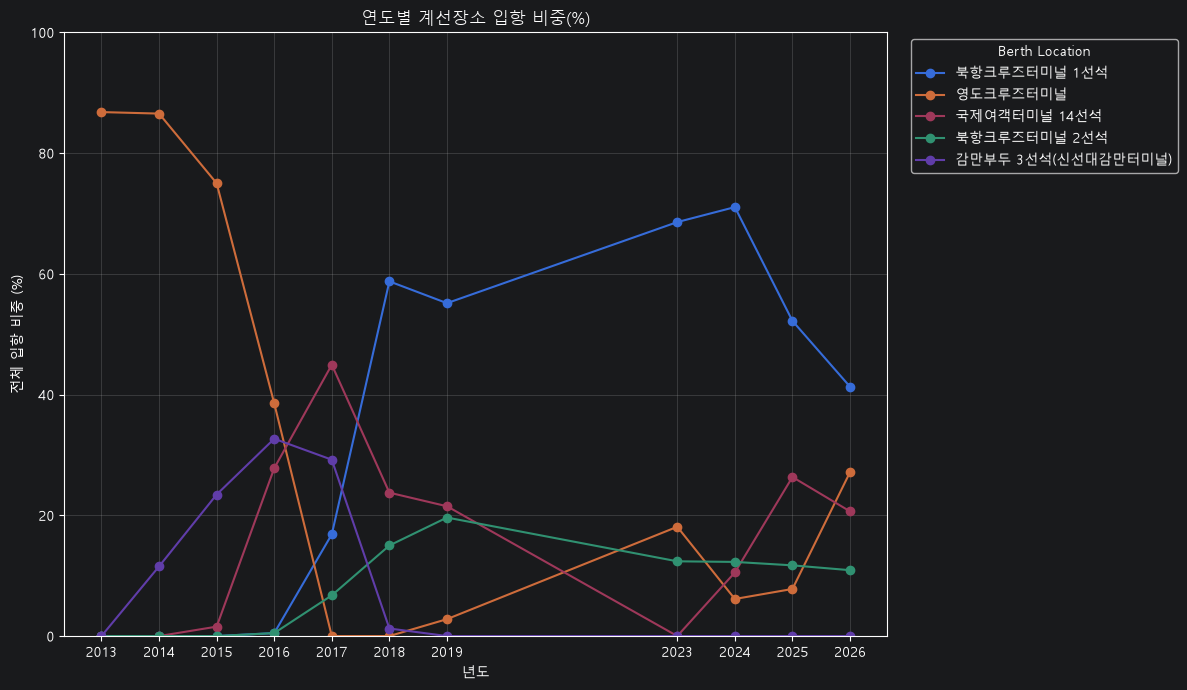

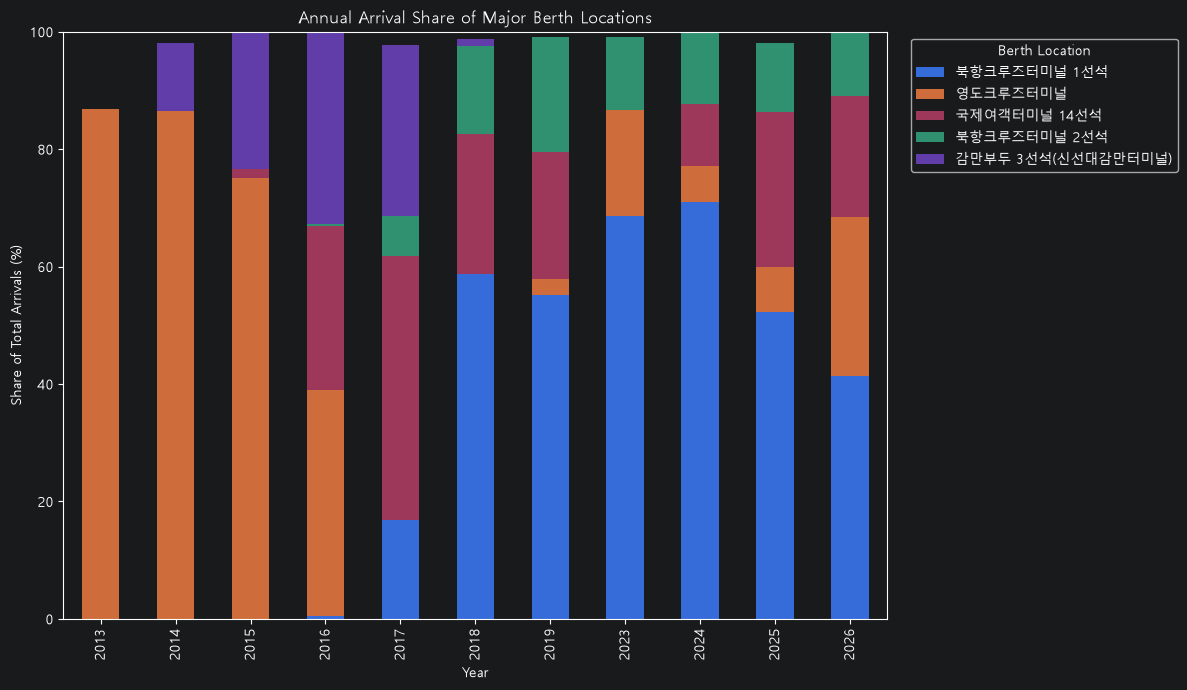

In [36]:
# 입항 횟수뿐 아니라 전체 입항 중 계선장소별 비중이 연도별로 어떻게 변했는지 확인
# 1. 입항일시에서 연도 추출
arrival["입항일시"] = pd.to_datetime(
    arrival["입항일시"], errors="coerce"
)
arrival["연도"] = arrival["입항일시"].dt.year

# 2. 연도별 전체 입항 횟수
yearly_total = arrival.groupby("연도").size()

# 3. 연도별 계선장소 입항 횟수
yearly_counts = (
    arrival.groupby(["연도", "계선장소.2"])
    .size()
    .unstack(fill_value=0)
    .sort_index()
)

# 4. 연도별 전체 입항 중 계선장소별 비중(%)
yearly_share = (
    yearly_counts
    .div(yearly_total, axis=0)
    .mul(100)
    .round(2)
)

print("연도별 전체 입항 횟수")
print(yearly_total)

print("\n연도별 계선장소 입항 비중(%)")
print(yearly_share.to_string())

# 5. 주요 계선장소 5곳의 비중 추이
top5 = (
    arrival["계선장소.2"]
    .value_counts()
    .head(5)
    .index
)

share_top5 = yearly_share.reindex(columns=top5)

ax = share_top5.plot(
    kind="line",
    marker="o",
    figsize=(12, 7)
)

ax.set_title("연도별 계선장소 입항 비중(%)")
ax.set_xlabel("년도")
ax.set_ylabel("전체 입항 비중 (%)")
ax.set_ylim(0, 100)
ax.set_xticks(yearly_share.index)
ax.grid(True, alpha=0.3)

plt.legend(
    title="Berth Location",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

# 6. 연도별 비중 누적 막대그래프
share_top5.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 7)
)

plt.title("Annual Arrival Share of Major Berth Locations")
plt.xlabel("Year")
plt.ylabel("Share of Total Arrivals (%)")
plt.legend(
    title="Berth Location",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.show()

# 7. 주요 계선장소 비중 결과 저장
yearly_share.to_csv(
    "연도별_계선장소별_입항비중.csv",
    encoding="utf-8-sig"
)


월별·선석별 입항 횟수
계선장소.2  1부두 14선석  감만부두 2선석(신선대감만터미널)  감만부두 3선석(신선대감만터미널)  감만부두 4선석(신선대감만터미널)  \
월                                                                              
1              0                   0                   9                   0   
2              0                   0                   9                   0   
3              1                   0                   8                   0   
4              2                   2                   7                   0   
5              1                   0                  14                   0   
6              1                   0                  10                   1   
7              0                   0                  11                   0   
8              1                   0                  10                   0   
9              0                   0                  11                   0   
10             1                   0                  10                   0   
11             0           

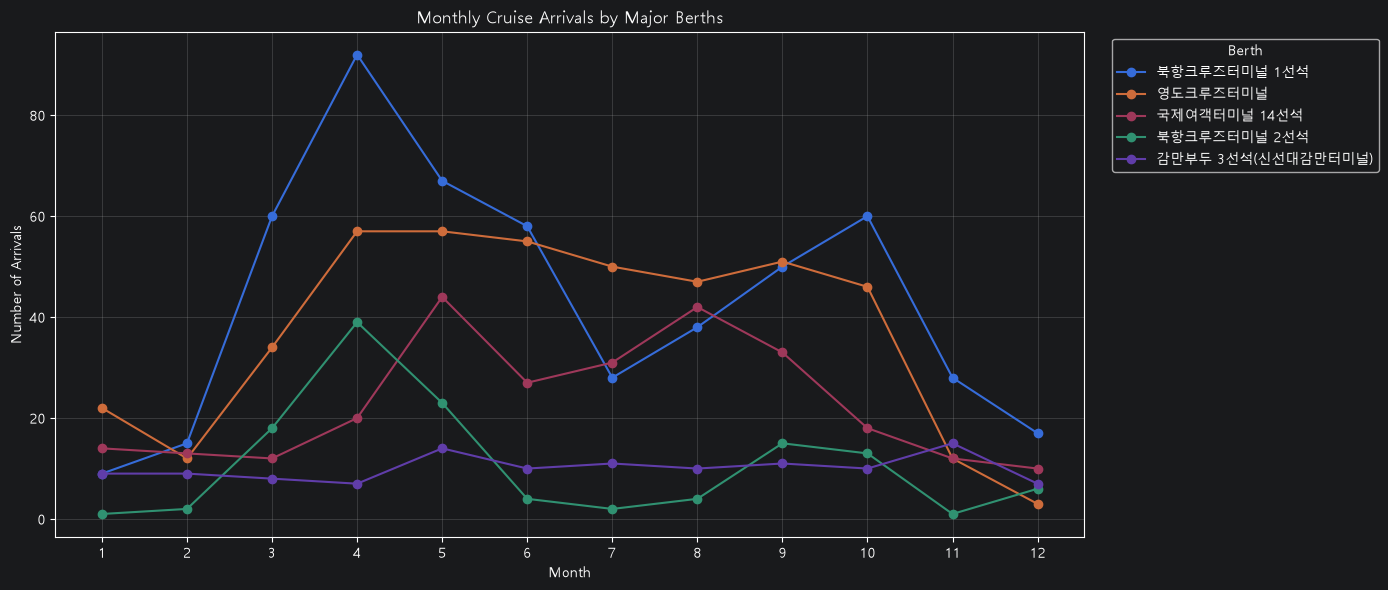

In [24]:


# 입항일시를 날짜 형식으로 변환
arrival["입항일시"] = pd.to_datetime(
    arrival["입항일시"], errors="coerce"
)

# 연도, 월 추출
arrival["연도"] = arrival["입항일시"].dt.year
arrival["월"] = arrival["입항일시"].dt.month

# 선석별 월간 입항 횟수
monthly_counts = (
    arrival.groupby(["월", "계선장소.2"])
    .size()
    .unstack(fill_value=0)
)

print("월별·선석별 입항 횟수")
print(monthly_counts)

# 선석별 월간 입항 횟수 그래프
top5_berths = arrival["계선장소.2"].value_counts().head(5).index

monthly_top5 = monthly_counts.reindex(columns=top5_berths)

monthly_top5.plot(
    figsize=(14, 6),
    marker="o"
)

plt.title("Monthly Cruise Arrivals by Major Berths")
plt.xlabel("Month")
plt.ylabel("Number of Arrivals")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.legend(title="Berth", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [25]:
print(
    df.groupby("입출")[["입항일시", "출항일시"]]
      .agg(["count", "min", "max"])
)

    입항일시                                    출항일시                    \
   count              min              max count               min   
입출                                                                   
입항  1518  2013-01-01 8:00  2026-10-16 7:00  1518  2013-01-03 17:00   
출항  1519  2013-01-01 8:00  2026-10-16 7:00  1519  2013-01-03 17:00   

                      
                 max  
입출                    
입항  2026-10-16 20:00  
출항  2026-10-16 20:00  


In [26]:
cols = [
    "입출", "선명", "호출부호",
    "계선장소.2", "입항일시", "출항일시"
]

print("입항 기록")
print(
    df[df["입출"] == "입항"][cols]
    .head(5)
    .to_string(index=False)
)

print("\n출항 기록")
print(
    df[df["입출"] == "출항"][cols]
    .head(5)
    .to_string(index=False)
)

입항 기록
입출           선명  호출부호   계선장소.2            입항일시             출항일시
입항 CLUB HARMONY V7XN2 영도크루즈터미널 2013-01-01 8:00 2013-01-03 17:00
입항 CLUB HARMONY V7XN2 영도크루즈터미널 2013-01-06 7:25 2013-01-07 18:00
입항 CLUB HARMONY V7XN2 영도크루즈터미널 2013-01-10 5:40 2013-01-10 17:00
입항 CLUB HARMONY V7XN2 영도크루즈터미널 2013-01-13 6:30 2013-01-13 18:00
입항 CLUB HARMONY V7XN2 영도크루즈터미널 2013-01-15 6:30 2013-01-15 17:00

출항 기록
입출           선명  호출부호   계선장소.2            입항일시             출항일시
출항 CLUB HARMONY V7XN2 영도크루즈터미널 2013-01-01 8:00 2013-01-03 17:00
출항 CLUB HARMONY V7XN2 영도크루즈터미널 2013-01-06 7:25 2013-01-07 18:00
출항 CLUB HARMONY V7XN2 영도크루즈터미널 2013-01-10 5:40 2013-01-10 17:00
출항 CLUB HARMONY V7XN2 영도크루즈터미널 2013-01-13 6:30 2013-01-13 18:00
출항 CLUB HARMONY V7XN2 영도크루즈터미널 2013-01-15 6:30 2013-01-15 17:00


In [27]:


# 입항 기록만 추출
arrival = df[df["입출"] == "입항"].copy()

# 날짜 형식 변환
arrival["입항일시"] = pd.to_datetime(arrival["입항일시"], errors="coerce")
arrival["출항일시"] = pd.to_datetime(arrival["출항일시"], errors="coerce")

# 체류시간 계산
arrival["체류시간_시간"] = (
    arrival["출항일시"] - arrival["입항일시"]
).dt.total_seconds() / 3600

# 계산 결과 확인
print(arrival[
    ["선명", "호출부호", "계선장소.2",
     "입항일시", "출항일시", "체류시간_시간"]
].head(10).to_string(index=False))

# 음수 체류시간 및 결측치 확인
print("\n체류시간 결측:", arrival["체류시간_시간"].isna().sum())
print("음수 체류시간:", (arrival["체류시간_시간"] < 0).sum())

          선명  호출부호   계선장소.2                입항일시                출항일시    체류시간_시간
CLUB HARMONY V7XN2 영도크루즈터미널 2013-01-01 08:00:00 2013-01-03 17:00:00  57.000000
CLUB HARMONY V7XN2 영도크루즈터미널 2013-01-06 07:25:00 2013-01-07 18:00:00  34.583333
CLUB HARMONY V7XN2 영도크루즈터미널 2013-01-10 05:40:00 2013-01-10 17:00:00  11.333333
CLUB HARMONY V7XN2 영도크루즈터미널 2013-01-13 06:30:00 2013-01-13 18:00:00  11.500000
CLUB HARMONY V7XN2 영도크루즈터미널 2013-01-15 06:30:00 2013-01-15 17:00:00  10.500000
CLUB HARMONY V7XN2 영도크루즈터미널 2013-01-17 07:00:00 2013-01-17 17:00:00  10.000000
CLUB HARMONY V7XN2 영도크루즈터미널 2013-01-20 07:30:00 2013-01-21 18:00:00  34.500000
CLUB HARMONY V7XN2 영도크루즈터미널 2013-01-24 06:30:00 2013-01-24 17:00:00  10.500000
CLUB HARMONY V7XN2 영도크루즈터미널 2013-01-27 07:50:00 2013-01-28 18:00:00  34.166667
CLUB HARMONY V7XN2 영도크루즈터미널 2013-01-31 06:45:00 2013-02-14 16:00:00 345.250000

체류시간 결측: 0
음수 체류시간: 0


In [28]:
berth_stay = (
    arrival.groupby("계선장소.2")["체류시간_시간"]
    .agg(
        입항건수="count",
        평균체류시간="mean",
        중앙값체류시간="median",
        최대체류시간="max"
    )
    .sort_values("평균체류시간", ascending=False)
    .round(2)
)

print(berth_stay)

                    입항건수  평균체류시간  중앙값체류시간  최대체류시간
계선장소.2                                           
남외항 N-4박지              4  162.00   152.00  272.00
국제여객터미널 14선석         276   31.61    10.19  322.00
수영박지(집단박지)             1   24.62    24.62   24.62
북항크루즈터미널 2선석         128   20.48    10.33  970.00
남외항 N-5박지              2   13.50    13.50   26.00
영도크루즈터미널             446   12.83    11.12  345.25
감만부두 4선석(신선대감만터미널)     1   12.50    12.50   12.50
북항크루즈터미널 1선석         522   11.51    10.62   62.18
감만부두 2선석(신선대감만터미널)     2   11.50    11.50   12.00
감만부두 3선석(신선대감만터미널)   121   11.11    11.07   35.00
신선대부두 5선석              1   11.00    11.00   11.00
자성대부두 64선석             4   10.48    10.56   12.00
국제여객터미널 10선석           1   10.00    10.00   10.00
신선대부두 2선석              1   10.00    10.00   10.00
1부두 14선석               7    9.28    10.83   11.17
국제여객터미널 13선석           1    7.50     7.50    7.50


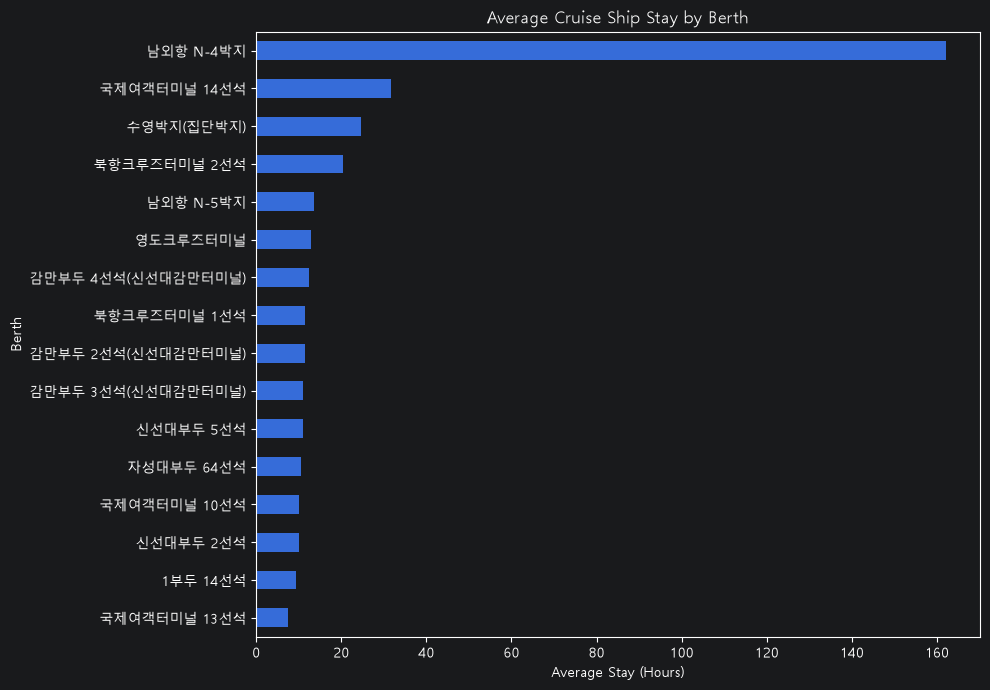

In [29]:
berth_stay["평균체류시간"].sort_values().plot(
    kind="barh",
    figsize=(10, 7)
)

plt.title("Average Cruise Ship Stay by Berth")
plt.xlabel("Average Stay (Hours)")
plt.ylabel("Berth")
plt.tight_layout()
plt.show()

In [30]:
# 체류시간이 72시간(3일)을 초과하는 기록 확인
long_stay = (
    arrival[arrival["체류시간_시간"] > 72]
    .sort_values("체류시간_시간", ascending=False)
)

print(
    long_stay[
        ["선명", "호출부호", "계선장소.2",
         "입항일시", "출항일시", "체류시간_시간"]
    ].to_string(index=False)
)

print("72시간 초과 기록 수:", len(long_stay))

           선명   호출부호       계선장소.2                입항일시                출항일시    체류시간_시간
EASTERN VENUS 3E7469 북항크루즈터미널 2선석 2025-03-16 08:00:00 2025-04-25 18:00:00 970.000000
 CLUB HARMONY  V7XN2     영도크루즈터미널 2013-01-31 06:45:00 2013-02-14 16:00:00 345.250000
EASTERN VENUS 3E7469 국제여객터미널 14선석 2025-05-24 08:00:00 2025-06-06 18:00:00 322.000000
EASTERN VENUS 3E7469 국제여객터미널 14선석 2025-05-11 08:00:00 2025-05-23 17:00:00 297.000000
EASTERN VENUS 3E7469    남외항 N-4박지 2025-12-13 10:00:00 2025-12-24 18:00:00 272.000000
EASTERN VENUS 3E7469    남외항 N-4박지 2025-03-06 14:00:00 2025-03-15 17:00:00 219.000000
EASTERN VENUS 3E7469 국제여객터미널 14선석 2026-01-11 08:00:00 2026-01-17 18:00:00 154.000000
EASTERN VENUS 3E7469 국제여객터미널 14선석 2025-11-01 20:00:00 2025-11-07 18:00:00 142.000000
EASTERN VENUS 3E7469 국제여객터미널 14선석 2026-05-18 08:00:00 2026-05-23 19:00:00 131.000000
EASTERN VENUS 3E7469 국제여객터미널 14선석 2025-06-29 08:00:00 2025-07-04 18:00:00 130.000000
EASTERN VENUS 3E7469 국제여객터미널 14선석 2025-07-06 08:00:00 2025-07-11 

In [31]:
# EASTERN VENUS 기록 확인
eastern = (
    arrival[arrival["선명"].str.strip() == "EASTERN VENUS"]
    .sort_values("입항일시")
    .copy()
)

print(
    eastern[
        [
            "선명", "계선장소.2",
            "입항일시", "출항일시", "체류시간_시간"
        ]
    ].to_string(index=False)
)

print("\n선석별 EASTERN VENUS 체류시간 요약")

print(
    eastern.groupby("계선장소.2")["체류시간_시간"]
    .agg(
        입항건수="count",
        평균체류시간="mean",
        중앙값체류시간="median",
        최대체류시간="max"
    )
    .round(2)
)

           선명       계선장소.2                입항일시                출항일시    체류시간_시간
EASTERN VENUS 북항크루즈터미널 2선석 2024-12-24 07:00:00 2024-12-24 20:00:00  13.000000
EASTERN VENUS 북항크루즈터미널 2선석 2024-12-28 07:00:00 2024-12-28 17:00:00  10.000000
EASTERN VENUS    남외항 N-4박지 2025-03-06 14:00:00 2025-03-15 17:00:00 219.000000
EASTERN VENUS 북항크루즈터미널 2선석 2025-03-16 08:00:00 2025-04-25 18:00:00 970.000000
EASTERN VENUS 국제여객터미널 14선석 2025-04-27 08:00:00 2025-05-01 15:00:00 103.000000
EASTERN VENUS 국제여객터미널 14선석 2025-05-06 09:00:00 2025-05-09 17:00:00  80.000000
EASTERN VENUS 국제여객터미널 14선석 2025-05-11 08:00:00 2025-05-23 17:00:00 297.000000
EASTERN VENUS 국제여객터미널 14선석 2025-05-24 08:00:00 2025-06-06 18:00:00 322.000000
EASTERN VENUS 국제여객터미널 14선석 2025-06-08 08:00:00 2025-06-13 18:00:00 130.000000
EASTERN VENUS 국제여객터미널 14선석 2025-06-15 09:00:00 2025-06-20 18:00:00 129.000000
EASTERN VENUS 국제여객터미널 14선석 2025-06-22 08:00:00 2025-06-27 18:00:00 130.000000
EASTERN VENUS 국제여객터미널 14선석 2025-06-29 08:00:00 2025-07-04 18:00:

In [32]:
# 전체 입항 기록 기준
berth_all = (
    arrival.groupby("계선장소.2")["체류시간_시간"]
    .agg(
        입항건수="count",
        평균체류시간="mean",
        중앙값체류시간="median",
        최대체류시간="max"
    )
)

# EASTERN VENUS 제외: 비교 분석용
arrival_without_ev = arrival[
    arrival["선명"].str.strip() != "EASTERN VENUS"
]

berth_without_ev = (
    arrival_without_ev.groupby("계선장소.2")["체류시간_시간"]
    .agg(
        입항건수="count",
        평균체류시간="mean",
        중앙값체류시간="median",
        최대체류시간="max"
    )
)

# 주요 선석 비교
compare = berth_all.join(
    berth_without_ev,
    lsuffix="_전체",
    rsuffix="_EASTERN_VENUS제외"
)

print(compare.round(2).to_string())

                    입항건수_전체  평균체류시간_전체  중앙값체류시간_전체  최대체류시간_전체  입항건수_EASTERN_VENUS제외  평균체류시간_EASTERN_VENUS제외  중앙값체류시간_EASTERN_VENUS제외  최대체류시간_EASTERN_VENUS제외
계선장소.2                                                                                                                                                      
1부두 14선석                  7       9.28       10.83      11.17                     7                    9.28                    10.83                   11.17
감만부두 2선석(신선대감만터미널)        2      11.50       11.50      12.00                     2                   11.50                    11.50                   12.00
감만부두 3선석(신선대감만터미널)      121      11.11       11.07      35.00                   121                   11.11                    11.07                   35.00
감만부두 4선석(신선대감만터미널)        1      12.50       12.50      12.50                     1                   12.50                    12.50                   12.50
국제여객터미널 10선석              1      10.00       10.00      10

In [45]:


# 입항일시와 출항일시를 날짜 형식으로 변환
df['입항일시'] = pd.to_datetime(
    df['입항일시'], errors='coerce'
)
df['출항일시'] = pd.to_datetime(
    df['출항일시'], errors='coerce'
)

# 체류시간 계산 (시간 단위)
df['체류시간_시간'] = (
    df['출항일시'] - df['입항일시']
).dt.total_seconds() / 3600

# 계산 결과 확인
print(df[
    ['선명', '입항일시', '출항일시', '계선장소.2', '체류시간_시간']
].head(10))

# 체류시간 계산 상태 확인
print("\n체류시간 결측치:", df['체류시간_시간'].isna().sum())
print("음수 체류시간:", (df['체류시간_시간'] < 0).sum())
print("전체 데이터 건수:", len(df))

             선명                입항일시                출항일시    계선장소.2    체류시간_시간
0  CLUB HARMONY 2013-01-01 08:00:00 2013-01-03 17:00:00  영도크루즈터미널  57.000000
1  CLUB HARMONY 2013-01-01 08:00:00 2013-01-03 17:00:00  영도크루즈터미널  57.000000
2  CLUB HARMONY 2013-01-06 07:25:00 2013-01-07 18:00:00  영도크루즈터미널  34.583333
3  CLUB HARMONY 2013-01-06 07:25:00 2013-01-07 18:00:00  영도크루즈터미널  34.583333
4  CLUB HARMONY 2013-01-10 05:40:00 2013-01-10 17:00:00  영도크루즈터미널  11.333333
5  CLUB HARMONY 2013-01-10 05:40:00 2013-01-10 17:00:00  영도크루즈터미널  11.333333
6  CLUB HARMONY 2013-01-13 06:30:00 2013-01-13 18:00:00  영도크루즈터미널  11.500000
7  CLUB HARMONY 2013-01-13 06:30:00 2013-01-13 18:00:00  영도크루즈터미널  11.500000
8  CLUB HARMONY 2013-01-15 06:30:00 2013-01-15 17:00:00  영도크루즈터미널  10.500000
9  CLUB HARMONY 2013-01-15 06:30:00 2013-01-15 17:00:00  영도크루즈터미널  10.500000

체류시간 결측치: 0
음수 체류시간: 0
전체 데이터 건수: 3037


In [48]:
# 1. 완전히 동일한 행의 중복 확인
print("완전 중복 행 수:", df.duplicated().sum())

# 2. 선박명 + 입항일시 + 출항일시 + 선석이 같은 기록 확인
key_cols = [
    '선명', '입항일시', '출항일시', '계선장소.2'
]

print(
    "동일 입출항·선석 기록의 중복 행 수:",
    df.duplicated(subset=key_cols).sum()
)

# 3. 중복이 의심되는 기록 예시
dup = df[
    df.duplicated(subset=key_cols, keep=False)
].sort_values(key_cols)

print("\n중복 의심 기록 상위 20행")
print(
    dup[
        key_cols + ['체류시간_시간', '입항횟수', '입항횟수.1']
    ].head(20).to_string(index=False)
)

# 4. 체류시간이 긴 기록 상위 15건
print("\n체류시간 상위 15행")
print(
    df.sort_values('체류시간_시간', ascending=False)[
        ['선명', '호출부호', '입항일시', '출항일시',
         '계선장소.2', '체류시간_시간']
    ].head(15).to_string(index=False)
)

완전 중복 행 수: 0
동일 입출항·선석 기록의 중복 행 수: 1503

중복 의심 기록 상위 20행
              선명                입항일시                출항일시   계선장소.2   체류시간_시간  입항횟수  입항횟수.1
ADORA MAGIC CITY 2026-01-01 09:05:00 2026-01-01 22:00:00 영도크루즈터미널 12.916667  2026       1
ADORA MAGIC CITY 2026-01-01 09:05:00 2026-01-01 22:00:00 영도크루즈터미널 12.916667  2026       1
ADORA MAGIC CITY 2026-01-05 09:00:00 2026-01-05 22:00:00 영도크루즈터미널 13.000000  2026       2
ADORA MAGIC CITY 2026-01-05 09:00:00 2026-01-05 22:00:00 영도크루즈터미널 13.000000  2026       2
ADORA MAGIC CITY 2026-01-09 09:00:00 2026-01-09 22:00:00 영도크루즈터미널 13.000000  2026       3
ADORA MAGIC CITY 2026-01-09 09:00:00 2026-01-09 22:00:00 영도크루즈터미널 13.000000  2026       3
ADORA MAGIC CITY 2026-01-13 09:35:00 2026-01-13 21:48:00 영도크루즈터미널 12.216667  2026       4
ADORA MAGIC CITY 2026-01-13 09:35:00 2026-01-13 21:48:00 영도크루즈터미널 12.216667  2026       4
ADORA MAGIC CITY 2026-01-17 09:00:00 2026-01-17 21:30:00 영도크루즈터미널 12.500000  2026       5
ADORA MAGIC CITY 2026-01-17 09:00:00 2026-0

In [49]:
# EASTERN VENUS의 장기 체류 기록 확인
mask = (
    df['선명'].astype(str).str.strip().eq('EASTERN VENUS')
    & (df['체류시간_시간'] >= 200)
)

cols = [
    '선명',
    '호출부호',
    '입항일시',
    '출항일시',
    '계선장소',
    '계선장소.1',
    '계선장소.2',
    '체류시간_시간'
]

print(
    df.loc[mask, cols]
    .sort_values(['입항일시', '출항일시'])
    .to_string(index=False)
)

# 동일한 입출항 시각에 선석이 몇 종류 연결되어 있는지 확인
event_cols = ['선명', '호출부호', '입항일시', '출항일시']

berth_check = (
    df.groupby(event_cols, dropna=False)
    .agg(
        행수=('계선장소.2', 'size'),
        선석종류수=('계선장소.2', 'nunique'),
        선석목록=('계선장소.2',
                  lambda x: ', '.join(
                      sorted(x.dropna().astype(str).unique())
                  ))
    )
    .reset_index()
)

print("\n동일 입출항 시각에 여러 선석이 연결된 기록")
print(
    berth_check[berth_check['선석종류수'] > 1]
    .sort_values('행수', ascending=False)
    .head(30)
    .to_string(index=False)
)

           선명   호출부호                입항일시                출항일시 계선장소  계선장소.1       계선장소.2  체류시간_시간
EASTERN VENUS 3E7469 2025-03-06 14:00:00 2025-03-15 17:00:00  WAN       4    남외항 N-4박지    219.0
EASTERN VENUS 3E7469 2025-03-06 14:00:00 2025-03-15 17:00:00  MBF       2 북항크루즈터미널 2선석    219.0
EASTERN VENUS 3E7469 2025-03-16 08:00:00 2025-04-25 18:00:00  MBF       2 북항크루즈터미널 2선석    970.0
EASTERN VENUS 3E7469 2025-03-16 08:00:00 2025-04-25 18:00:00  MBF      14 국제여객터미널 14선석    970.0
EASTERN VENUS 3E7469 2025-05-11 08:00:00 2025-05-23 17:00:00  MBF      14 국제여객터미널 14선석    297.0
EASTERN VENUS 3E7469 2025-05-11 08:00:00 2025-05-23 17:00:00  MBF      14 국제여객터미널 14선석    297.0
EASTERN VENUS 3E7469 2025-05-24 08:00:00 2025-06-06 18:00:00  MBF      14 국제여객터미널 14선석    322.0
EASTERN VENUS 3E7469 2025-05-24 08:00:00 2025-06-06 18:00:00  MBF      14 국제여객터미널 14선석    322.0
EASTERN VENUS 3E7469 2025-12-13 10:00:00 2025-12-24 18:00:00  MBF      14 국제여객터미널 14선석    272.0
EASTERN VENUS 3E7469 2025-12-13 10:00:00

In [50]:
# EASTERN VENUS의 장기 체류 기록 확인
mask = (
    df['선명'].astype(str).str.strip().eq('EASTERN VENUS')
    & (df['체류시간_시간'] >= 200)
)

cols = [
    '선명',
    '호출부호',
    '입항일시',
    '출항일시',
    '계선장소',
    '계선장소.1',
    '계선장소.2',
    '체류시간_시간'
]

print(
    df.loc[mask, cols]
    .sort_values(['입항일시', '출항일시'])
    .to_string(index=False)
)

# 동일한 입출항 시각에 선석이 몇 종류 연결되어 있는지 확인
event_cols = ['선명', '호출부호', '입항일시', '출항일시']

berth_check = (
    df.groupby(event_cols, dropna=False)
    .agg(
        행수=('계선장소.2', 'size'),
        선석종류수=('계선장소.2', 'nunique'),
        선석목록=('계선장소.2',
                  lambda x: ', '.join(
                      sorted(x.dropna().astype(str).unique())
                  ))
    )
    .reset_index()
)

print("\n동일 입출항 시각에 여러 선석이 연결된 기록")
print(
    berth_check[berth_check['선석종류수'] > 1]
    .sort_values('행수', ascending=False)
    .head(30)
    .to_string(index=False)
)

           선명   호출부호                입항일시                출항일시 계선장소  계선장소.1       계선장소.2  체류시간_시간
EASTERN VENUS 3E7469 2025-03-06 14:00:00 2025-03-15 17:00:00  WAN       4    남외항 N-4박지    219.0
EASTERN VENUS 3E7469 2025-03-06 14:00:00 2025-03-15 17:00:00  MBF       2 북항크루즈터미널 2선석    219.0
EASTERN VENUS 3E7469 2025-03-16 08:00:00 2025-04-25 18:00:00  MBF       2 북항크루즈터미널 2선석    970.0
EASTERN VENUS 3E7469 2025-03-16 08:00:00 2025-04-25 18:00:00  MBF      14 국제여객터미널 14선석    970.0
EASTERN VENUS 3E7469 2025-05-11 08:00:00 2025-05-23 17:00:00  MBF      14 국제여객터미널 14선석    297.0
EASTERN VENUS 3E7469 2025-05-11 08:00:00 2025-05-23 17:00:00  MBF      14 국제여객터미널 14선석    297.0
EASTERN VENUS 3E7469 2025-05-24 08:00:00 2025-06-06 18:00:00  MBF      14 국제여객터미널 14선석    322.0
EASTERN VENUS 3E7469 2025-05-24 08:00:00 2025-06-06 18:00:00  MBF      14 국제여객터미널 14선석    322.0
EASTERN VENUS 3E7469 2025-12-13 10:00:00 2025-12-24 18:00:00  MBF      14 국제여객터미널 14선석    272.0
EASTERN VENUS 3E7469 2025-12-13 10:00:00

In [51]:
# EASTERN VENUS의 동일 입출항 건 중
# 여러 선석에 연결된 기록의 모든 컬럼 비교

target_date = pd.Timestamp('2025-03-16 08:00:00')

check = df[
    (df['선명'].astype(str).str.strip() == 'EASTERN VENUS')
    & (df['입항일시'] == target_date)
]

# 모든 컬럼 출력
with pd.option_context(
    'display.max_columns', None,
    'display.width', 300,
    'display.max_colwidth', 50
):
    print(check.T.to_string())

                                     1983                 1984
항명                                     부산                   부산
호출부호                               3E7469               3E7469
선명                          EASTERN VENUS        EASTERN VENUS
입항횟수                                 2025                 2025
입항횟수.1                                  2                    2
구분                                     최종                   최종
외내                                     외항                   외항
입출                                     입항                   출항
총톤수                                26,594               26,594
입항일시                  2025-03-16 08:00:00  2025-03-16 08:00:00
출항일시                  2025-04-25 18:00:00  2025-04-25 18:00:00
CIQ수속일자                   2025-03-16 9:00     2025-04-25 17:00
수리일시                     2025-04-28 11:33     2025-04-28 11:35
항해구분                                   기타                   기타
MRN 번호                        25PKNS0316I          25PK

In [52]:
# EASTERN VENUS의 입출 구분별 기록 수
ev = df[
    df['선명'].astype(str).str.strip().eq('EASTERN VENUS')
].copy()

print(
    ev.groupby(['입출', '계선장소.2'], dropna=False)
      .size()
      .unstack(fill_value=0)
      .to_string()
)

# 동일한 입출항 기간에 입항·출항 행이 각각 몇 개 있는지 확인
event_cols = ['선명', '호출부호', '입항일시', '출항일시']

print("\n입출 구분별 기록 수")
print(
    ev.groupby(event_cols + ['입출'], dropna=False)
      .size()
      .unstack(fill_value=0)
      .to_string()
)

계선장소.2  국제여객터미널 13선석  국제여객터미널 14선석  남외항 N-4박지  북항크루즈터미널 2선석
입출                                                         
입항                 0            98          3             3
출항                 1           100          0             3

입출 구분별 기록 수
입출                                                            입항  출항
선명            호출부호   입항일시                출항일시                       
EASTERN VENUS 3E7469 2024-12-24 07:00:00 2024-12-24 20:00:00   1   1
                     2024-12-28 07:00:00 2024-12-28 17:00:00   1   1
                     2025-03-06 14:00:00 2025-03-15 17:00:00   1   1
                     2025-03-16 08:00:00 2025-04-25 18:00:00   1   1
                     2025-04-27 08:00:00 2025-05-01 15:00:00   1   1
                     2025-05-06 09:00:00 2025-05-09 17:00:00   1   1
                     2025-05-11 08:00:00 2025-05-23 17:00:00   1   1
                     2025-05-24 08:00:00 2025-06-06 18:00:00   1   1
                     2025-06-08 08:00:00 2025-06-13 18:00

In [53]:
# 1. 입항 행만 사용한 선석별 체류시간 통계
arrivals = df[df['입출'].astype(str).str.strip() == '입항'].copy()

berth_stats = (
    arrivals.groupby('계선장소.2')['체류시간_시간']
    .agg(
        입항건수='count',
        평균체류시간='mean',
        중앙값체류시간='median',
        최대체류시간='max'
    )
    .round(2)
)

print("=== 입항 행 기준 선석별 통계 ===")
print(berth_stats.to_string())


# 2. 입항·출항 신고의 선석이 다른 기항 건 확인
event_cols = ['선명', '호출부호', '입항일시', '출항일시']

pivot = (
    df.pivot_table(
        index=event_cols,
        columns='입출',
        values='계선장소.2',
        aggfunc=lambda x: ' / '.join(sorted(set(x.dropna().astype(str))))
    )
    .reset_index()
)

if '입항' in pivot.columns and '출항' in pivot.columns:
    mismatch = pivot[
        pivot['입항'].notna()
        & pivot['출항'].notna()
        & (pivot['입항'] != pivot['출항'])
    ]

    print("\n=== 입항·출항 선석이 다른 기항 건 ===")
    print("건수:", len(mismatch))
    print(mismatch.head(30).to_string(index=False))
else:
    print("입항 또는 출항 데이터가 부족해 비교할 수 없습니다.")

=== 입항 행 기준 선석별 통계 ===
                    입항건수  평균체류시간  중앙값체류시간  최대체류시간
계선장소.2                                           
1부두 14선석               7    9.28    10.83   11.17
감만부두 2선석(신선대감만터미널)     2   11.50    11.50   12.00
감만부두 3선석(신선대감만터미널)   121   11.11    11.07   35.00
감만부두 4선석(신선대감만터미널)     1   12.50    12.50   12.50
국제여객터미널 10선석           1   10.00    10.00   10.00
국제여객터미널 13선석           1    7.50     7.50    7.50
국제여객터미널 14선석         276   31.61    10.19  322.00
남외항 N-4박지              4  162.00   152.00  272.00
남외항 N-5박지              2   13.50    13.50   26.00
북항크루즈터미널 1선석         522   11.51    10.62   62.18
북항크루즈터미널 2선석         128   20.48    10.33  970.00
수영박지(집단박지)             1   24.62    24.62   24.62
신선대부두 2선석              1   10.00    10.00   10.00
신선대부두 5선석              1   11.00    11.00   11.00
영도크루즈터미널             446   12.83    11.12  345.25
자성대부두 64선석             4   10.48    10.56   12.00

=== 입항·출항 선석이 다른 기항 건 ===
건수: 15
                선명    호출부호                입

In [54]:
# 입항 기록만 별도 분석용 데이터로 사용
arrivals = df[
    df['입출'].astype(str).str.strip() == '입항'
].copy()

# 분석 대상 선석
target_berths = [
    '국제여객터미널 14선석',
    '북항크루즈터미널 2선석',
    '남외항 N-4박지'
]

# 선석별 체류시간 상위 10건
long_stays = (
    arrivals[
        arrivals['계선장소.2'].isin(target_berths)
    ]
    .sort_values('체류시간_시간', ascending=False)
    .groupby('계선장소.2', group_keys=False)
    .head(10)
    [[
        '계선장소.2',
        '선명',
        '호출부호',
        '입항일시',
        '출항일시',
        '체류시간_시간'
    ]]
)

print(long_stays.to_string(index=False))


# EASTERN VENUS 포함/제외 통계 비교
def summarize(data):
    return (
        data.groupby('계선장소.2')['체류시간_시간']
        .agg(['count', 'mean', 'median', 'max'])
        .rename(columns={
            'count': '입항건수',
            'mean': '평균체류시간',
            'median': '중앙값체류시간',
            'max': '최대체류시간'
        })
        .round(2)
    )

all_stats = summarize(
    arrivals[arrivals['계선장소.2'].isin(target_berths)]
)

without_ev = summarize(
    arrivals[
        arrivals['계선장소.2'].isin(target_berths)
        & arrivals['선명'].astype(str).str.strip().ne('EASTERN VENUS')
    ]
)

print("\n=== 전체 통계 ===")
print(all_stats)

print("\n=== EASTERN VENUS 제외 통계 ===")
print(without_ev)

print("\n=== 통계 변화: 제외 - 전체 ===")
print((without_ev - all_stats).round(2))

      계선장소.2               선명   호출부호                입항일시                출항일시  체류시간_시간
북항크루즈터미널 2선석    EASTERN VENUS 3E7469 2025-03-16 08:00:00 2025-04-25 18:00:00   970.00
국제여객터미널 14선석    EASTERN VENUS 3E7469 2025-05-24 08:00:00 2025-06-06 18:00:00   322.00
국제여객터미널 14선석    EASTERN VENUS 3E7469 2025-05-11 08:00:00 2025-05-23 17:00:00   297.00
   남외항 N-4박지    EASTERN VENUS 3E7469 2025-12-13 10:00:00 2025-12-24 18:00:00   272.00
   남외항 N-4박지    EASTERN VENUS 3E7469 2025-03-06 14:00:00 2025-03-15 17:00:00   219.00
국제여객터미널 14선석    EASTERN VENUS 3E7469 2026-01-11 08:00:00 2026-01-17 18:00:00   154.00
국제여객터미널 14선석    EASTERN VENUS 3E7469 2025-11-01 20:00:00 2025-11-07 18:00:00   142.00
국제여객터미널 14선석    EASTERN VENUS 3E7469 2026-05-18 08:00:00 2026-05-23 19:00:00   131.00
국제여객터미널 14선석    EASTERN VENUS 3E7469 2025-10-19 08:00:00 2025-10-24 18:00:00   130.00
국제여객터미널 14선석    EASTERN VENUS 3E7469 2026-04-12 08:00:00 2026-04-17 18:00:00   130.00
국제여객터미널 14선석    EASTERN VENUS 3E7469 2025-07-06 08:00:

In [55]:

# 날짜형식 보정
df['입항일시'] = pd.to_datetime(df['입항일시'], errors='coerce')
df['출항일시'] = pd.to_datetime(df['출항일시'], errors='coerce')

# EASTERN VENUS의 2025년 3~6월 기록
ev = df[
    df['선명'].astype(str).str.strip().eq('EASTERN VENUS')
    & df['입항일시'].between(
        '2025-03-01', '2025-06-30 23:59:59'
    )
].copy()

# 입항·출항 행과 계선장소를 함께 확인
cols = [
    '선명',
    '호출부호',
    '입출',
    'MRN 번호',
    '입항일시',
    '출항일시',
    '체류시간_시간',
    '계선장소',
    '계선장소.1',
    '계선장소.2',
    '전출항지',
    '차항지'
]

print(
    ev[cols]
    .sort_values(['입항일시', '입출', 'MRN 번호'])
    .to_string(index=False)
)

           선명   호출부호 입출      MRN 번호                입항일시                출항일시  체류시간_시간 계선장소  계선장소.1       계선장소.2               전출항지                차항지
EASTERN VENUS 3E7469 입항 25PKNS0306I 2025-03-06 14:00:00 2025-03-15 17:00:00    219.0  WAN       4    남외항 N-4박지                 여수             SASEBO
EASTERN VENUS 3E7469 출항 25PKNS0306E 2025-03-06 14:00:00 2025-03-15 17:00:00    219.0  MBF       2 북항크루즈터미널 2선석                 여수 TSUSHIMA, NAGASAKI
EASTERN VENUS 3E7469 입항 25PKNS0316I 2025-03-16 08:00:00 2025-04-25 18:00:00    970.0  MBF       2 북항크루즈터미널 2선석 TSUSHIMA, NAGASAKI     OCEAN DISTRICT
EASTERN VENUS 3E7469 출항 25PKNS0316E 2025-03-16 08:00:00 2025-04-25 18:00:00    970.0  MBF      14 국제여객터미널 14선석 TSUSHIMA, NAGASAKI     OCEAN DISTRICT
EASTERN VENUS 3E7469 입항 25PKNS0427I 2025-04-27 08:00:00 2025-05-01 15:00:00    103.0  MBF      14 국제여객터미널 14선석             SASEBO  KEELUNG (CHILUNG)
EASTERN VENUS 3E7469 출항 25PKNS0427E 2025-04-27 08:00:00 2025-05-01 15:00:00    103.0  MBF      14 국제여객터미널 

In [56]:
# EASTERN VENUS 입항 기록만 추출
ev_arrivals = (
    df[
        df['선명'].astype(str).str.strip().eq('EASTERN VENUS')
        & df['입출'].astype(str).str.strip().eq('입항')
    ]
    .copy()
    .sort_values('입항일시')
)

# 다음 입항 기록과의 시간 간격 계산
ev_arrivals['다음입항일시'] = ev_arrivals['입항일시'].shift(-1)

ev_arrivals['다음입항까지_시간'] = (
    ev_arrivals['다음입항일시'] - ev_arrivals['입항일시']
).dt.total_seconds() / 3600

# 핵심 정보 출력
cols = [
    '입항일시',
    '출항일시',
    '체류시간_시간',
    '계선장소.2',
    '전출항지',
    '차항지',
    '다음입항일시',
    '다음입항까지_시간'
]

print(ev_arrivals[cols].to_string(index=False))

               입항일시                출항일시    체류시간_시간       계선장소.2               전출항지                차항지              다음입항일시   다음입항까지_시간
2024-12-24 07:00:00 2024-12-24 20:00:00  13.000000 북항크루즈터미널 2선석        SHIMONOSEKI             SASEBO 2024-12-28 07:00:00   96.000000
2024-12-28 07:00:00 2024-12-28 17:00:00  10.000000 북항크루즈터미널 2선석          KAGOSHIMA                 여수 2025-03-06 14:00:00 1639.000000
2025-03-06 14:00:00 2025-03-15 17:00:00 219.000000    남외항 N-4박지                 여수             SASEBO 2025-03-16 08:00:00  234.000000
2025-03-16 08:00:00 2025-04-25 18:00:00 970.000000 북항크루즈터미널 2선석 TSUSHIMA, NAGASAKI     OCEAN DISTRICT 2025-04-27 08:00:00 1008.000000
2025-04-27 08:00:00 2025-05-01 15:00:00 103.000000 국제여객터미널 14선석             SASEBO  KEELUNG (CHILUNG) 2025-05-06 09:00:00  217.000000
2025-05-06 09:00:00 2025-05-09 17:00:00  80.000000 국제여객터미널 14선석           ISHIGAKI             SASEBO 2025-05-11 08:00:00  119.000000
2025-05-11 08:00:00 2025-05-23 17:00:00 297.000000 국제여객터미널 14선

In [57]:

ev_arrivals = (
    df[
        df['선명'].astype(str).str.strip().eq('EASTERN VENUS')
        & df['입출'].astype(str).str.strip().eq('입항')
    ]
    .copy()
    .sort_values('입항일시')
)

# 체류시간 유형 분류
ev_arrivals['체류유형'] = pd.cut(
    ev_arrivals['체류시간_시간'],
    bins=[-np.inf, 24, 72, 168, np.inf],
    labels=[
        '24시간 이하',
        '24~72시간',
        '72~168시간',
        '168시간 초과'
    ],
    right=True
)

# 유형별 건수 및 체류시간 요약
summary = (
    ev_arrivals.groupby('체류유형', observed=False)
    ['체류시간_시간']
    .agg(
        입항건수='count',
        평균체류시간='mean',
        중앙값체류시간='median',
        최대체류시간='max'
    )
    .round(2)
)

print(summary)

# 장기 체류 기록 확인
long_stays = (
    ev_arrivals[
        ev_arrivals['체류시간_시간'] > 168
    ][[
        '입항일시',
        '출항일시',
        '체류시간_시간',
        '계선장소.2',
        '전출항지',
        '차항지'
    ]]
    .sort_values('체류시간_시간', ascending=False)
)

print("\n=== 168시간 초과 기록 ===")
print(long_stays.to_string(index=False))

          입항건수  평균체류시간  중앙값체류시간  최대체류시간
체류유형                                   
24시간 이하     36   10.07     10.0    23.0
24~72시간     18   53.03     57.0    72.0
72~168시간    45  110.98    106.0   154.0
168시간 초과     5  416.00    297.0   970.0

=== 168시간 초과 기록 ===
               입항일시                출항일시  체류시간_시간       계선장소.2               전출항지                차항지
2025-03-16 08:00:00 2025-04-25 18:00:00    970.0 북항크루즈터미널 2선석 TSUSHIMA, NAGASAKI     OCEAN DISTRICT
2025-05-24 08:00:00 2025-06-06 18:00:00    322.0 국제여객터미널 14선석 TSUSHIMA, NAGASAKI          KAGOSHIMA
2025-05-11 08:00:00 2025-05-23 17:00:00    297.0 국제여객터미널 14선석             SASEBO TSUSHIMA, NAGASAKI
2025-12-13 10:00:00 2025-12-24 18:00:00    272.0    남외항 N-4박지                 여수     HAKATA/FUKUOKA
2025-03-06 14:00:00 2025-03-15 17:00:00    219.0    남외항 N-4박지                 여수             SASEBO


In [58]:
# EASTERN VENUS 입항 기록
ev_arrivals = (
    df[
        df['선명'].astype(str).str.strip().eq('EASTERN VENUS')
        & df['입출'].astype(str).str.strip().eq('입항')
    ]
    .copy()
)

# 전체 기록과 168시간 이하 기록 비교
comparison = pd.DataFrame({
    '전체 기록': ev_arrivals['체류시간_시간'].agg(
        ['count', 'mean', 'median', 'max']
    ),
    '168시간 이하': ev_arrivals.loc[
        ev_arrivals['체류시간_시간'] <= 168,
        '체류시간_시간'
    ].agg(['count', 'mean', 'median', 'max'])
}).T

comparison = comparison.rename(columns={
    'count': '입항건수',
    'mean': '평균체류시간',
    'median': '중앙값체류시간',
    'max': '최대체류시간'
}).round(2)

print(comparison)

           입항건수  평균체류시간  중앙값체류시간  최대체류시간
전체 기록     104.0   80.68     60.0   970.0
168시간 이하   99.0   63.75     58.0   154.0


In [59]:

# 입항 기록만 추출
arrivals = df[
    df['입출'].astype(str).str.strip().eq('입항')
].copy()

# 체류시간이 유효한 기록만 사용
arrivals = arrivals[
    arrivals['체류시간_시간'].notna()
    & (arrivals['체류시간_시간'] >= 0)
].copy()

# EASTERN VENUS와 그 외 선박 구분
arrivals['선박구분'] = np.where(
    arrivals['선명'].astype(str).str.strip().eq('EASTERN VENUS'),
    'EASTERN VENUS',
    '그 외 선박'
)

# 전체 기록 및 168시간 이하 기록 비교
results = []

for group_name, group in arrivals.groupby('선박구분'):
    for condition, subset in [
        ('전체 기록', group),
        ('168시간 이하', group[group['체류시간_시간'] <= 168])
    ]:
        results.append({
            '선박구분': group_name,
            '분석조건': condition,
            '입항건수': len(subset),
            '평균체류시간': subset['체류시간_시간'].mean(),
            '중앙값체류시간': subset['체류시간_시간'].median(),
            '90백분위수': subset['체류시간_시간'].quantile(0.9),
            '최대체류시간': subset['체류시간_시간'].max()
        })

comparison = pd.DataFrame(results)

print(comparison.round(2).to_string(index=False))

         선박구분     분석조건  입항건수  평균체류시간  중앙값체류시간  90백분위수  최대체류시간
EASTERN VENUS    전체 기록   104   80.68     60.0   130.0  970.00
EASTERN VENUS 168시간 이하    99   63.75     58.0   130.0  154.00
       그 외 선박    전체 기록  1414   11.96     11.0    14.0  345.25
       그 외 선박 168시간 이하  1413   11.72     11.0    14.0   85.00


In [60]:
# 장기 체류 기록 추출: 오류 판정이 아닌 검증 후보
long_stays = arrivals[
    arrivals['체류시간_시간'] > 168
].copy()

cols = [
    '선명',
    '호출부호',
    '입항일시',
    '출항일시',
    '체류시간_시간',
    '계선장소.2',
    '전출항지',
    '차항지',
    'MRN 번호'
]

long_stays = long_stays[cols].sort_values(
    '체류시간_시간',
    ascending=False
)

print(long_stays.to_string(index=False))

           선명   호출부호                입항일시                출항일시  체류시간_시간       계선장소.2               전출항지                차항지      MRN 번호
EASTERN VENUS 3E7469 2025-03-16 08:00:00 2025-04-25 18:00:00   970.00 북항크루즈터미널 2선석 TSUSHIMA, NAGASAKI     OCEAN DISTRICT 25PKNS0316I
 CLUB HARMONY  V7XN2 2013-01-31 06:45:00 2013-02-14 16:00:00   345.25     영도크루즈터미널        BEPPU, OITA                 옥포 13UNIHA0249
EASTERN VENUS 3E7469 2025-05-24 08:00:00 2025-06-06 18:00:00   322.00 국제여객터미널 14선석 TSUSHIMA, NAGASAKI          KAGOSHIMA 25PKNS0524I
EASTERN VENUS 3E7469 2025-05-11 08:00:00 2025-05-23 17:00:00   297.00 국제여객터미널 14선석             SASEBO TSUSHIMA, NAGASAKI 25PKNS0511I
EASTERN VENUS 3E7469 2025-12-13 10:00:00 2025-12-24 18:00:00   272.00    남외항 N-4박지                 여수     HAKATA/FUKUOKA 25PKNS1213I
EASTERN VENUS 3E7469 2025-03-06 14:00:00 2025-03-15 17:00:00   219.00    남외항 N-4박지                 여수             SASEBO 25PKNS0306I


In [61]:


# 장기 체류 기록의 식별 키
long_keys = long_stays[
    ['선명', '호출부호', '입항일시', '출항일시']
].drop_duplicates()

# 원본 데이터에서 해당 기록의 입항/출항 행 찾기
check = df.copy()

check['선명'] = check['선명'].astype(str).str.strip()
check['호출부호'] = check['호출부호'].astype(str).str.strip()
check['입출'] = check['입출'].astype(str).str.strip()

check['입항일시'] = pd.to_datetime(
    check['입항일시'], errors='coerce'
)
check['출항일시'] = pd.to_datetime(
    check['출항일시'], errors='coerce'
)

long_keys['선명'] = long_keys['선명'].astype(str).str.strip()
long_keys['호출부호'] = long_keys['호출부호'].astype(str).str.strip()

detail = check.merge(
    long_keys,
    on=['선명', '호출부호', '입항일시', '출항일시'],
    how='inner'
)

cols = [
    '선명', '입출', '입항일시', '출항일시',
    '계선장소', '계선장소.1', '계선장소.2',
    'MRN 번호', '전출항지', '차항지'
]

print(
    detail[cols]
    .sort_values(['선명', '입항일시', '입출'])
    .to_string(index=False)
)

           선명 입출                입항일시                출항일시 계선장소  계선장소.1       계선장소.2      MRN 번호               전출항지                차항지
 CLUB HARMONY 입항 2013-01-31 06:45:00 2013-02-14 16:00:00  MBY       1     영도크루즈터미널 13UNIHA0249        BEPPU, OITA                 옥포
 CLUB HARMONY 출항 2013-01-31 06:45:00 2013-02-14 16:00:00  MBY       1     영도크루즈터미널 13UNIHD0248        BEPPU, OITA                 목포
EASTERN VENUS 입항 2025-03-06 14:00:00 2025-03-15 17:00:00  WAN       4    남외항 N-4박지 25PKNS0306I                 여수             SASEBO
EASTERN VENUS 출항 2025-03-06 14:00:00 2025-03-15 17:00:00  MBF       2 북항크루즈터미널 2선석 25PKNS0306E                 여수 TSUSHIMA, NAGASAKI
EASTERN VENUS 입항 2025-03-16 08:00:00 2025-04-25 18:00:00  MBF       2 북항크루즈터미널 2선석 25PKNS0316I TSUSHIMA, NAGASAKI     OCEAN DISTRICT
EASTERN VENUS 출항 2025-03-16 08:00:00 2025-04-25 18:00:00  MBF      14 국제여객터미널 14선석 25PKNS0316E TSUSHIMA, NAGASAKI     OCEAN DISTRICT
EASTERN VENUS 입항 2025-05-11 08:00:00 2025-05-23 17:00:00  MBF      14

In [64]:


# 입항 기록 중 선석으로 표시된 사례만 추출
berth_arrivals = arrivals[
    arrivals['계선장소.2'].astype(str).str.contains('선석', na=False)
].copy()

# 선석별 체류시간 통계 계산
berth_summary = (
    berth_arrivals
    .groupby('계선장소.2')['체류시간_시간']
    .agg([
        ('입항건수', 'count'),
        ('평균체류시간', 'mean'),
        ('중앙값체류시간', 'median'),
        ('90백분위수', lambda x: x.quantile(0.9)),
        ('최대체류시간', 'max')
    ])
    .round(2)
    .sort_values('평균체류시간', ascending=False)
)

print(berth_summary.to_string())

                    입항건수  평균체류시간  중앙값체류시간  90백분위수  최대체류시간
계선장소.2                                                   
국제여객터미널 14선석         276   31.61    10.19  106.00  322.00
북항크루즈터미널 2선석         128   20.48    10.33   27.17  970.00
감만부두 4선석(신선대감만터미널)     1   12.50    12.50   12.50   12.50
북항크루즈터미널 1선석         522   11.51    10.62   13.73   62.18
감만부두 2선석(신선대감만터미널)     2   11.50    11.50   11.90   12.00
감만부두 3선석(신선대감만터미널)   121   11.11    11.07   12.68   35.00
신선대부두 5선석              1   11.00    11.00   11.00   11.00
자성대부두 64선석             4   10.48    10.56   11.74   12.00
신선대부두 2선석              1   10.00    10.00   10.00   10.00
국제여객터미널 10선석           1   10.00    10.00   10.00   10.00
1부두 14선석               7    9.28    10.83   11.10   11.17
국제여객터미널 13선석           1    7.50     7.50    7.50    7.50


In [65]:
# 선석별 전체 기록과 168시간 이하 기록 비교
berth_arrivals = arrivals[
    arrivals['계선장소.2'].astype(str).str.contains('선석', na=False)
].copy()

results = []

for berth, group in berth_arrivals.groupby('계선장소.2'):
    for condition, subset in [
        ('전체', group),
        ('168시간 이하', group[group['체류시간_시간'] <= 168])
    ]:
        results.append({
            '선석': berth,
            '분석조건': condition,
            '입항건수': len(subset),
            '평균체류시간': subset['체류시간_시간'].mean(),
            '중앙값체류시간': subset['체류시간_시간'].median(),
            '90백분위수': subset['체류시간_시간'].quantile(0.9),
            '최대체류시간': subset['체류시간_시간'].max()
        })

berth_comparison = pd.DataFrame(results)

print(
    berth_comparison
    .round(2)
    .sort_values(['선석', '분석조건'])
    .to_string(index=False)
)

                선석     분석조건  입항건수  평균체류시간  중앙값체류시간  90백분위수  최대체류시간
          1부두 14선석 168시간 이하     7    9.28    10.83   11.10   11.17
          1부두 14선석       전체     7    9.28    10.83   11.10   11.17
감만부두 2선석(신선대감만터미널) 168시간 이하     2   11.50    11.50   11.90   12.00
감만부두 2선석(신선대감만터미널)       전체     2   11.50    11.50   11.90   12.00
감만부두 3선석(신선대감만터미널) 168시간 이하   121   11.11    11.07   12.68   35.00
감만부두 3선석(신선대감만터미널)       전체   121   11.11    11.07   12.68   35.00
감만부두 4선석(신선대감만터미널) 168시간 이하     1   12.50    12.50   12.50   12.50
감만부두 4선석(신선대감만터미널)       전체     1   12.50    12.50   12.50   12.50
      국제여객터미널 10선석 168시간 이하     1   10.00    10.00   10.00   10.00
      국제여객터미널 10선석       전체     1   10.00    10.00   10.00   10.00
      국제여객터미널 13선석 168시간 이하     1    7.50     7.50    7.50    7.50
      국제여객터미널 13선석       전체     1    7.50     7.50    7.50    7.50
      국제여객터미널 14선석 168시간 이하   274   29.58    10.13  105.37  154.00
      국제여객터미널 14선석       전체   276   31.61    10.19  106.00  32

In [66]:
# 국제여객터미널 14선석의 장기 체류 기록
ipt14 = arrivals[
    arrivals['계선장소.2'].astype(str).str.strip().eq(
        '국제여객터미널 14선석'
    )
].copy()

long_ipt14 = ipt14[
    ipt14['체류시간_시간'] > 24
].copy()

# 선박별 장기 체류 요약
ship_summary = (
    long_ipt14
    .groupby('선명')
    .agg(
        장기체류건수=('체류시간_시간', 'count'),
        평균체류시간=('체류시간_시간', 'mean'),
        최대체류시간=('체류시간_시간', 'max')
    )
    .round(2)
    .sort_values(
        ['장기체류건수', '최대체류시간'],
        ascending=False
    )
)

print(ship_summary.head(20).to_string())

# 가장 긴 기록 20건 확인
cols = [
    '선명', '입항일시', '출항일시',
    '체류시간_시간', '계선장소.2',
    '전출항지', '차항지', 'MRN 번호'
]

print(
    long_ipt14[cols]
    .sort_values('체류시간_시간', ascending=False)
    .head(20)
    .to_string(index=False)
)

                    장기체류건수  평균체류시간  최대체류시간
선명                                        
EASTERN VENUS           64  101.49  322.00
코스타네오로멘티카                1   76.15   76.15
SKYSEA GOLDEN ERA        1   38.00   38.00
COSTA NEOROMANTICA       1   35.00   35.00
           선명                입항일시                출항일시  체류시간_시간       계선장소.2               전출항지                차항지      MRN 번호
EASTERN VENUS 2025-05-24 08:00:00 2025-06-06 18:00:00    322.0 국제여객터미널 14선석 TSUSHIMA, NAGASAKI          KAGOSHIMA 25PKNS0524I
EASTERN VENUS 2025-05-11 08:00:00 2025-05-23 17:00:00    297.0 국제여객터미널 14선석             SASEBO TSUSHIMA, NAGASAKI 25PKNS0511I
EASTERN VENUS 2026-01-11 08:00:00 2026-01-17 18:00:00    154.0 국제여객터미널 14선석             SASEBO             SASEBO 26PKNS0111I
EASTERN VENUS 2025-11-01 20:00:00 2025-11-07 18:00:00    142.0 국제여객터미널 14선석                 포항 TSUSHIMA, NAGASAKI 25PKNS1101I
EASTERN VENUS 2026-05-18 08:00:00 2026-05-23 19:00:00    131.0 국제여객터미널 14선석        SAKAIMINATO     HAKATA/FUKUOK

In [67]:


# EASTERN VENUS 입항 기록
ev = arrivals[
    arrivals['선명'].astype(str).str.strip().eq('EASTERN VENUS')
].copy()

ev = ev.sort_values('입항일시').reset_index(drop=True)

# 다음 입항 시각
ev['다음입항일시'] = ev['입항일시'].shift(-1)

# 출항 후 다음 입항까지의 공백 시간
ev['출항후_다음입항까지_시간'] = (
    ev['다음입항일시'] - ev['출항일시']
).dt.total_seconds() / 3600

# 체류시간이 24시간 초과인 기록만 확인
long_ev = ev[ev['체류시간_시간'] > 24].copy()

cols = [
    '입항일시',
    '출항일시',
    '체류시간_시간',
    '다음입항일시',
    '출항후_다음입항까지_시간',
    '계선장소.2',
    '전출항지',
    '차항지'
]

print(
    long_ev[cols]
    .sort_values('입항일시')
    .to_string(index=False)
)

               입항일시                출항일시    체류시간_시간              다음입항일시  출항후_다음입항까지_시간       계선장소.2               전출항지                차항지
2025-03-06 14:00:00 2025-03-15 17:00:00 219.000000 2025-03-16 08:00:00      15.000000    남외항 N-4박지                 여수             SASEBO
2025-03-16 08:00:00 2025-04-25 18:00:00 970.000000 2025-04-27 08:00:00      38.000000 북항크루즈터미널 2선석 TSUSHIMA, NAGASAKI     OCEAN DISTRICT
2025-04-27 08:00:00 2025-05-01 15:00:00 103.000000 2025-05-06 09:00:00     114.000000 국제여객터미널 14선석             SASEBO  KEELUNG (CHILUNG)
2025-05-06 09:00:00 2025-05-09 17:00:00  80.000000 2025-05-11 08:00:00      39.000000 국제여객터미널 14선석           ISHIGAKI             SASEBO
2025-05-11 08:00:00 2025-05-23 17:00:00 297.000000 2025-05-24 08:00:00      15.000000 국제여객터미널 14선석             SASEBO TSUSHIMA, NAGASAKI
2025-05-24 08:00:00 2025-06-06 18:00:00 322.000000 2025-06-08 08:00:00      38.000000 국제여객터미널 14선석 TSUSHIMA, NAGASAKI          KAGOSHIMA
2025-06-08 08:00:00 2025-06-13 18:00:00 1

In [68]:


# 원본 데이터 보존
data = df.copy()

# 날짜형 변환
date_cols = ["입항일시", "출항일시", "다음입항일시"]

for col in date_cols:
    data[col] = pd.to_datetime(data[col], errors="coerce")

# 체류시간 재계산
data["체류시간_계산"] = (
    data["출항일시"] - data["입항일시"]
).dt.total_seconds() / 3600

# 출항 후 공백 재계산
data["출항후_공백_계산"] = (
    data["다음입항일시"] - data["출항일시"]
).dt.total_seconds() / 3600

# 다음 행의 실제 입항일시와 비교
data = data.sort_values("입항일시").reset_index(drop=True)

data["실제_다음행_입항일시"] = data["입항일시"].shift(-1)

data["다음입항_일치"] = (
    data["다음입항일시"].eq(data["실제_다음행_입항일시"])
    | (
        data["다음입항일시"].isna()
        & data["실제_다음행_입항일시"].isna()
    )
)

# 데이터 점검
print("전체 행 수:", len(data))
print("\n다음 입항일시 일치 여부")
print(data["다음입항_일치"].value_counts(dropna=False))

print("\n체류시간 요약")
print(data["체류시간_계산"].describe())

print("\n출항 후 공백 요약")
print(data["출항후_공백_계산"].describe())

print("\n공백시간 음수 또는 누락")
print(
    data.loc[
        (data["출항후_공백_계산"] < 0)
        | data["출항후_공백_계산"].isna(),
        [
            "입항일시", "출항일시", "다음입항일시",
            "실제_다음행_입항일시", "출항후_공백_계산"
        ]
    ].to_string(index=False)
)

# 공백시간 구간별 빈도
valid_gap = data["출항후_공백_계산"].dropna()

bins = [-np.inf, 24, 48, 72, 120, np.inf]
labels = ["24시간 이하", "24~48시간", "48~72시간",
          "72~120시간", "120시간 초과"]

data["공백구간"] = pd.cut(
    data["출항후_공백_계산"],
    bins=bins,
    labels=labels,
    right=True
)

print("\n공백시간 구간별 빈도")
print(data["공백구간"].value_counts(sort=False))

# 장기 체류 기준: 120시간 초과
data["장기체류"] = data["체류시간_계산"] > 120

print("\n장기 체류 여부별 체류시간 및 공백시간")
print(
    data.groupby("장기체류", observed=True)[
        ["체류시간_계산", "출항후_공백_계산"]
    ].agg(["count", "mean", "median", "max"]).round(2)
)

# 체류시간과 공백시간의 상관관계
corr_data = data[
    ["체류시간_계산", "출항후_공백_계산"]
].dropna()

print("\n체류시간-공백시간 상관계수")
print(corr_data.corr().round(3))

# 민감도 분석: 전체 vs 장기 체류 제외
def summarize(series):
    return pd.Series({
        "표본수": series.count(),
        "평균": series.mean(),
        "중앙값": series.median(),
        "표준편차": series.std(),
        "최댓값": series.max(),
        "120시간 초과 건수": (series > 120).sum(),
        "120시간 초과 비중(%)": (series > 120).mean() * 100
    })

base = data["체류시간_계산"].dropna()
without_long = data.loc[
    data["체류시간_계산"] <= 120, "체류시간_계산"
].dropna()

sensitivity = pd.DataFrame({
    "전체 기록": summarize(base),
    "120시간 초과 제외": summarize(without_long)
}).T

print("\n체류시간 민감도 분석")
print(sensitivity.round(2))

# 공백 24시간 이하 기록의 상세 확인
print("\n공백 24시간 이하 기록")
print(
    data.loc[
        data["출항후_공백_계산"].between(0, 24),
        [
            "입항일시", "출항일시", "체류시간_계산",
            "다음입항일시", "출항후_공백_계산",
            "계선장소.2", "전출항지", "차항지"
        ]
    ].to_string(index=False)
)

# 시각화 1: 체류시간 분포
plt.figure(figsize=(9, 5))
plt.hist(base, bins=25, edgecolor="black")
plt.axvline(120, linestyle="--", label="120시간 기준")
plt.xlabel("체류시간 (시간)")
plt.ylabel("입항 건수")
plt.title("체류시간 분포")
plt.legend()
plt.tight_layout()
plt.show()

# 시각화 2: 체류시간과 출항 후 공백
plot_data = data.dropna(
    subset=["체류시간_계산", "출항후_공백_계산"]
)

plt.figure(figsize=(9, 5))
plt.scatter(
    plot_data["체류시간_계산"],
    plot_data["출항후_공백_계산"],
    alpha=0.7
)
plt.xlabel("체류시간 (시간)")
plt.ylabel("출항 후 공백 (시간)")
plt.title("체류시간과 출항 후 공백의 관계")
plt.tight_layout()
plt.show()


KeyError: '다음입항일시'

In [69]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3037 entries, 0 to 3036
Data columns (total 33 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   항명                   3037 non-null   str           
 1   호출부호                 3037 non-null   str           
 2   선명                   3037 non-null   str           
 3   입항횟수                 3037 non-null   int64         
 4   입항횟수.1               3037 non-null   int64         
 5   구분                   3037 non-null   str           
 6   외내                   3037 non-null   str           
 7   입출                   3037 non-null   str           
 8   총톤수                  3037 non-null   str           
 9   입항일시                 3037 non-null   datetime64[us]
 10  출항일시                 3037 non-null   datetime64[us]
 11  CIQ수속일자              3037 non-null   str           
 12  수리일시                 3035 non-null   str           
 13  항해구분                 3037 non-null   str    

In [70]:


# 1. EASTERN VENUS 데이터만 추출
ship = df.loc[df["선명"].str.strip().str.upper() == "EASTERN VENUS"].copy()

# 2. 입항일시 기준 정렬
ship = ship.sort_values("입항일시").reset_index(drop=True)

# 3. 다음 입항일시 계산
ship["다음입항일시"] = ship["입항일시"].shift(-1)

# 4. 출항 후 다음 입항까지 공백 계산
ship["출항후_다음입항까지_시간"] = (
    ship["다음입항일시"] - ship["출항일시"]
).dt.total_seconds() / 3600

# 5. 입항 간격 계산
ship["입항간격_시간"] = (
    ship["다음입항일시"] - ship["입항일시"]
).dt.total_seconds() / 3600

# 6. 분석 결과 확인
cols = [
    "입항일시",
    "출항일시",
    "체류시간_시간",
    "다음입항일시",
    "입항간격_시간",
    "출항후_다음입항까지_시간",
    "계선장소.2",
    "전출항지",
    "차항지"
]

print("EASTERN VENUS 입항 기록:", len(ship))
print(ship[cols].to_string(index=False))


EASTERN VENUS 입항 기록: 208
               입항일시                출항일시    체류시간_시간              다음입항일시     입항간격_시간  출항후_다음입항까지_시간       계선장소.2               전출항지                차항지
2024-12-24 07:00:00 2024-12-24 20:00:00  13.000000 2024-12-24 07:00:00    0.000000     -13.000000 북항크루즈터미널 2선석        SHIMONOSEKI             SASEBO
2024-12-24 07:00:00 2024-12-24 20:00:00  13.000000 2024-12-28 07:00:00   96.000000      83.000000 북항크루즈터미널 2선석        SHIMONOSEKI             SASEBO
2024-12-28 07:00:00 2024-12-28 17:00:00  10.000000 2024-12-28 07:00:00    0.000000     -10.000000 북항크루즈터미널 2선석          KAGOSHIMA                 여수
2024-12-28 07:00:00 2024-12-28 17:00:00  10.000000 2025-03-06 14:00:00 1639.000000    1629.000000 북항크루즈터미널 2선석          KAGOSHIMA                 여수
2025-03-06 14:00:00 2025-03-15 17:00:00 219.000000 2025-03-06 14:00:00    0.000000    -219.000000    남외항 N-4박지                 여수             SASEBO
2025-03-06 14:00:00 2025-03-15 17:00:00 219.000000 2025-03-16 08:00:00  234.00000

월별 입항 건수
월                   1   2   3   4   5   6   7   8   9   10  11  12
계선장소명                                                             
1부두 14선석             0   0   1   2   1   1   0   1   0   1   0   0
감만부두 2선석(신선대감만터미널)   0   0   0   2   0   0   0   0   0   0   0   0
감만부두 3선석(신선대감만터미널)   9   9   8   7  14  10  11  10  11  10  15   7
감만부두 4선석(신선대감만터미널)   0   0   0   0   0   1   0   0   0   0   0   0
국제여객터미널 10선석         0   0   0   0   0   0   0   1   0   0   0   0
국제여객터미널 13선석         1   0   0   0   0   0   0   0   0   0   0   0
국제여객터미널 14선석         8   8   4  13  33  17  25  33  29  14  12  10
남외항 N-4박지            0   0   1   0   0   0   0   0   0   1   1   1
남외항 N-5박지            0   0   1   0   0   0   0   0   0   1   0   0
북항크루즈터미널 1선석         6   7  38  69  49  40  15  27  36  50  28  17
북항크루즈터미널 2선석         0   1   9  33  17   2   0   3   8  11   1   6
수영박지(집단박지)           0   0   0   0   0   0   0   0   0   1   0   0
신선대부두 2선석            0   0   0   0   0   0   1   0   

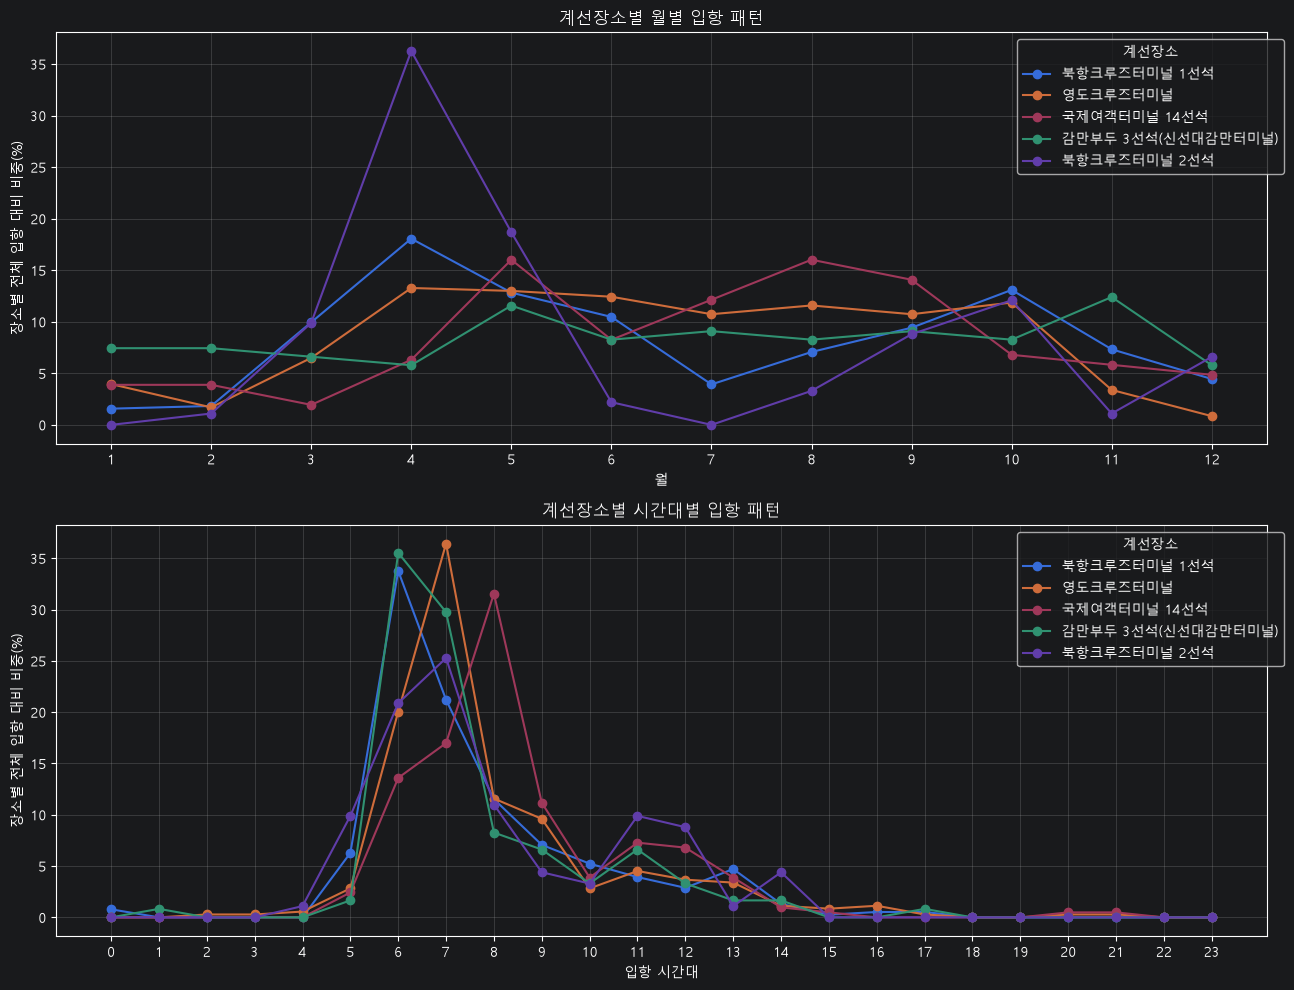

In [71]:


# 1. 입항 기록만 선택
arrival = df.loc[
    df["입출"].astype("string").str.strip().eq("입항")
].copy()

arrival["입항일시"] = pd.to_datetime(
    arrival["입항일시"], errors="coerce"
)

arrival = arrival.dropna(subset=["입항일시", "계선장소.2"])
arrival = arrival.rename(columns={"계선장소.2": "계선장소명"})

# 2. 일부 기간만 있는 2026년 제외
arrival = arrival[arrival["입항일시"].dt.year < 2026].copy()

arrival["월"] = arrival["입항일시"].dt.month
arrival["시간"] = arrival["입항일시"].dt.hour

# 3. 장소별 월별·시간대별 입항 건수
monthly_count = pd.crosstab(
    arrival["계선장소명"], arrival["월"]
).reindex(columns=range(1, 13), fill_value=0)

hourly_count = pd.crosstab(
    arrival["계선장소명"], arrival["시간"]
).reindex(columns=range(24), fill_value=0)

# 4. 각 장소의 전체 입항 중 해당 월·시간대가 차지하는 비중
monthly_pct = monthly_count.div(
    monthly_count.sum(axis=1), axis=0
) * 100

hourly_pct = hourly_count.div(
    hourly_count.sum(axis=1), axis=0
) * 100

print("월별 입항 건수")
print(monthly_count)

print("\n시간대별 입항 건수")
print(hourly_count)

# 5. 주요 5개 장소의 패턴 비교
top_places = arrival["계선장소명"].value_counts().head(5).index

plt.rcParams["font.family"] = "Malgun Gothic"  # Windows 한글 폰트
plt.rcParams["axes.unicode_minus"] = False

fig, axes = plt.subplots(2, 1, figsize=(13, 10))

monthly_pct.loc[top_places].T.plot(
    ax=axes[0], marker="o"
)
axes[0].set(
    title="계선장소별 월별 입항 패턴",
    xlabel="월",
    ylabel="장소별 전체 입항 대비 비중(%)"
)
axes[0].set_xticks(range(1, 13))

hourly_pct.loc[top_places].T.plot(
    ax=axes[1], marker="o"
)
axes[1].set(
    title="계선장소별 시간대별 입항 패턴",
    xlabel="입항 시간대",
    ylabel="장소별 전체 입항 대비 비중(%)"
)
axes[1].set_xticks(range(24))

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(title="계선장소", bbox_to_anchor=(1.02, 1))

plt.tight_layout()
plt.show()

In [72]:
print(hourly_count.to_string())

시간                  0   1   2   3   4   5    6    7   8   9   10  11  12  13  14  15  16  17  18  19  20  21  22  23
계선장소명                                                                                                               
1부두 14선석             0   0   0   0   0   0    3    1   0   0   0   0   2   0   1   0   0   0   0   0   0   0   0   0
감만부두 2선석(신선대감만터미널)   0   0   0   0   0   0    2    0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
감만부두 3선석(신선대감만터미널)   0   1   0   0   0   2   43   36  10   8   4   8   4   2   2   0   0   1   0   0   0   0   0   0
감만부두 4선석(신선대감만터미널)   0   0   0   0   0   0    0    0   0   1   0   0   0   0   0   0   0   0   0   0   0   0   0   0
국제여객터미널 10선석         0   0   0   0   0   0    0    1   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
국제여객터미널 13선석         0   0   0   0   0   0    0    1   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
국제여객터미널 14선석         0   0   0   0   0   5   28   35  65  23   8

In [73]:
# 1. 출항일시를 날짜·시간 형식으로 변환
arrival["출항일시"] = pd.to_datetime(
    arrival["출항일시"], errors="coerce"
)

# 2. 체류시간 계산: 시간 단위
arrival["체류시간"] = (
    arrival["출항일시"] - arrival["입항일시"]
).dt.total_seconds() / 3600

# 3. 출항일시 누락과 음수 체류시간 확인
print("출항일시 누락:", arrival["출항일시"].isna().sum())
print("음수 체류시간:", arrival["체류시간"].lt(0).sum())

# 누락·음수 제외
stay = arrival.loc[arrival["체류시간"].ge(0)].copy()

# 4. 계선장소별 체류시간 비교
stay_summary = (
    stay.groupby("계선장소명")["체류시간"]
    .agg(
        유효건수="count",
        평균체류시간="mean",
        중앙값체류시간="median",
        최대체류시간="max"
    )
    .sort_values("유효건수", ascending=False)
)

print(stay_summary.round(2).to_string())

출항일시 누락: 0
음수 체류시간: 0
                    유효건수  평균체류시간  중앙값체류시간  최대체류시간
계선장소명                                            
북항크루즈터미널 1선석         382   11.51    10.59   62.18
영도크루즈터미널             354   12.93    11.00  345.25
국제여객터미널 14선석         206   25.90    10.04  322.00
감만부두 3선석(신선대감만터미널)   121   11.11    11.07   35.00
북항크루즈터미널 2선석          91   23.46    10.02  970.00
1부두 14선석               7    9.28    10.83   11.17
자성대부두 64선석             4   10.48    10.56   12.00
남외항 N-4박지              4  162.00   152.00  272.00
남외항 N-5박지              2   13.50    13.50   26.00
감만부두 2선석(신선대감만터미널)     2   11.50    11.50   12.00
감만부두 4선석(신선대감만터미널)     1   12.50    12.50   12.50
국제여객터미널 13선석           1    7.50     7.50    7.50
국제여객터미널 10선석           1   10.00    10.00   10.00
수영박지(집단박지)             1   24.62    24.62   24.62
신선대부두 5선석              1   11.00    11.00   11.00
신선대부두 2선석              1   10.00    10.00   10.00


In [74]:
# 체류시간이 긴 기록부터 10개 확인
print(
    stay.nlargest(10, "체류시간")[
        ["선명", "계선장소명", "입항일시", "출항일시", "체류시간"]
    ].to_string(index=False)
)

           선명        계선장소명                입항일시                출항일시   체류시간
EASTERN VENUS 북항크루즈터미널 2선석 2025-03-16 08:00:00 2025-04-25 18:00:00 970.00
 CLUB HARMONY     영도크루즈터미널 2013-01-31 06:45:00 2013-02-14 16:00:00 345.25
EASTERN VENUS 국제여객터미널 14선석 2025-05-24 08:00:00 2025-06-06 18:00:00 322.00
EASTERN VENUS 국제여객터미널 14선석 2025-05-11 08:00:00 2025-05-23 17:00:00 297.00
EASTERN VENUS    남외항 N-4박지 2025-12-13 10:00:00 2025-12-24 18:00:00 272.00
EASTERN VENUS    남외항 N-4박지 2025-03-06 14:00:00 2025-03-15 17:00:00 219.00
EASTERN VENUS 국제여객터미널 14선석 2025-11-01 20:00:00 2025-11-07 18:00:00 142.00
EASTERN VENUS 국제여객터미널 14선석 2025-06-08 08:00:00 2025-06-13 18:00:00 130.00
EASTERN VENUS 국제여객터미널 14선석 2025-06-22 08:00:00 2025-06-27 18:00:00 130.00
EASTERN VENUS 국제여객터미널 14선석 2025-06-29 08:00:00 2025-07-04 18:00:00 130.00


In [75]:

# 입항일시와 출항일시가 모두 같은 중복 기록 확인
dup = ship.loc[
    ship.duplicated(
        subset=["입항일시", "출항일시"],
        keep=False
    )
].sort_values(["입항일시", "출항일시"])

print("중복으로 의심되는 행 수:", len(dup))
print(
    dup[
        [
            "입항일시", "출항일시", "선명",
            "호출부호", "MRN 번호", "계선장소.2",
            "체류시간_시간"
        ]
    ].to_string(index=False)
)

# 입항일시별 중복 횟수 상위 확인
print("\n입항일시 중복 횟수")
print(
    ship.groupby("입항일시").size()
        .sort_values(ascending=False)
        .head(20)
)


중복으로 의심되는 행 수: 208
               입항일시                출항일시            선명   호출부호      MRN 번호       계선장소.2    체류시간_시간
2024-12-24 07:00:00 2024-12-24 20:00:00 EASTERN VENUS 3E7469 24PKNS1224I 북항크루즈터미널 2선석  13.000000
2024-12-24 07:00:00 2024-12-24 20:00:00 EASTERN VENUS 3E7469 24PKNS1224E 북항크루즈터미널 2선석  13.000000
2024-12-28 07:00:00 2024-12-28 17:00:00 EASTERN VENUS 3E7469 24PKNS1228I 북항크루즈터미널 2선석  10.000000
2024-12-28 07:00:00 2024-12-28 17:00:00 EASTERN VENUS 3E7469 24PKNS1228E 북항크루즈터미널 2선석  10.000000
2025-03-06 14:00:00 2025-03-15 17:00:00 EASTERN VENUS 3E7469 25PKNS0306I    남외항 N-4박지 219.000000
2025-03-06 14:00:00 2025-03-15 17:00:00 EASTERN VENUS 3E7469 25PKNS0306E 북항크루즈터미널 2선석 219.000000
2025-03-16 08:00:00 2025-04-25 18:00:00 EASTERN VENUS 3E7469 25PKNS0316I 북항크루즈터미널 2선석 970.000000
2025-03-16 08:00:00 2025-04-25 18:00:00 EASTERN VENUS 3E7469 25PKNS0316E 국제여객터미널 14선석 970.000000
2025-04-27 08:00:00 2025-05-01 15:00:00 EASTERN VENUS 3E7469 25PKNS0427I 국제여객터미널 14선석 103.000000
2025-04-27 

In [76]:



ship_raw = df.loc[
    df["선명"].str.strip().str.upper().eq("EASTERN VENUS")
].copy()

# MRN 번호 끝의 I/E 구분 추출
ship_raw["신고구분"] = (
    ship_raw["MRN 번호"].astype(str).str.strip().str[-1]
)

# 동일한 입항·출항 시각별 I/E 행 개수
pair_check = (
    ship_raw.groupby(["입항일시", "출항일시"])
    .agg(
        행수=("MRN 번호", "size"),
        신고구분수=("신고구분", "nunique"),
        신고구분목록=("신고구분", lambda x: ", ".join(sorted(set(x)))),
        MRN목록=("MRN 번호", lambda x: ", ".join(x.astype(str))),
        계선장소수=("계선장소.2", "nunique"),
        계선장소목록=("계선장소.2", lambda x: " / ".join(x.astype(str).unique()))
    )
    .reset_index()
)

print("원본 행 수:", len(ship_raw))
print("고유 입출항 시각 조합 수:", len(pair_check))

print("\nI/E 쌍이 확인되는 행")
print(
    pair_check.loc[
        (pair_check["행수"] == 2)
        & (pair_check["신고구분수"] == 2)
    ].to_string(index=False)
)

print("\n입출항 시각이 같아도 I/E 쌍이 아닌 경우")
print(
    pair_check.loc[
        ~(
            (pair_check["행수"] == 2)
            & (pair_check["신고구분수"] == 2)
        )
    ].to_string(index=False)
)


원본 행 수: 208
고유 입출항 시각 조합 수: 104

I/E 쌍이 확인되는 행
               입항일시                출항일시  행수  신고구분수 신고구분목록                    MRN목록  계선장소수                      계선장소목록
2024-12-24 07:00:00 2024-12-24 20:00:00   2      2   E, I 24PKNS1224I, 24PKNS1224E      1                북항크루즈터미널 2선석
2024-12-28 07:00:00 2024-12-28 17:00:00   2      2   E, I 24PKNS1228I, 24PKNS1228E      1                북항크루즈터미널 2선석
2025-03-06 14:00:00 2025-03-15 17:00:00   2      2   E, I 25PKNS0306I, 25PKNS0306E      2    남외항 N-4박지 / 북항크루즈터미널 2선석
2025-03-16 08:00:00 2025-04-25 18:00:00   2      2   E, I 25PKNS0316I, 25PKNS0316E      2 북항크루즈터미널 2선석 / 국제여객터미널 14선석
2025-04-27 08:00:00 2025-05-01 15:00:00   2      2   E, I 25PKNS0427I, 25PKNS0427E      1                국제여객터미널 14선석
2025-05-06 09:00:00 2025-05-09 17:00:00   2      2   E, I 25PKNS0506E, 25PKNS0506I      1                국제여객터미널 14선석
2025-05-11 08:00:00 2025-05-23 17:00:00   2      2   E, I 25PKNS0511E, 25PKNS0511I      1                국제여객터미널 14선석
2025-05-2

In [77]:


# 1. 동일한 입·출항 시각 조합을 한 건으로 통합
ship_104 = (
    ship_raw.groupby(
        ["입항일시", "출항일시"],
        as_index=False,
        sort=True
    )
    .agg(
        체류시간_시간=("체류시간_시간", "first"),
        계선장소목록=(
            "계선장소.2",
            lambda x: " / ".join(
                pd.unique(x.dropna().astype(str))
            )
        ),
        MRN목록=(
            "MRN 번호",
            lambda x: " / ".join(x.astype(str))
        ),
        전출항지=("전출항지", "first"),
        차항지=("차항지", "first")
    )
    .sort_values("입항일시")
    .reset_index(drop=True)
)

# 2. 다음 입항일시와 입항 간격 계산
ship_104["다음입항일시"] = ship_104["입항일시"].shift(-1)

ship_104["입항간격_시간"] = (
    ship_104["다음입항일시"] - ship_104["입항일시"]
).dt.total_seconds() / 3600

ship_104["출항후_다음입항까지_시간"] = (
    ship_104["다음입항일시"] - ship_104["출항일시"]
).dt.total_seconds() / 3600

# 3. 데이터 검증
print("통합 전:", len(ship_raw))
print("통합 후:", len(ship_104))
print(
    "계선장소가 여러 개인 기록:",
    ship_104["계선장소목록"].str.contains(" / ", regex=False).sum()
)
print(
    "음수 공백 기록:",
    (ship_104["출항후_다음입항까지_시간"] < 0).sum()
)

# 4. 공백시간 구간별 분포
valid = ship_104.dropna(
    subset=["출항후_다음입항까지_시간"]
).copy()

bins = [-np.inf, 24, 48, 72, 120, np.inf]
labels = [
    "24시간 이하", "24~48시간", "48~72시간",
    "72~120시간", "120시간 초과"
]

valid["공백구간"] = pd.cut(
    valid["출항후_다음입항까지_시간"],
    bins=bins,
    labels=labels
)

print("\n=== 출항 후 공백시간 분포 ===")
print(
    valid["공백구간"]
    .value_counts(sort=False)
    .to_frame("건수")
    .assign(비중_pct=lambda x: (x["건수"] / len(valid) * 100).round(1))
)

print("\n=== 체류시간 및 공백시간 요약 ===")
print(
    valid[
        ["체류시간_시간", "입항간격_시간",
         "출항후_다음입항까지_시간"]
    ].describe().round(2)
)

# 5. 장기 체류 제외 전후 비교
def summarize(s):
    return pd.Series({
        "건수": s.count(),
        "평균": s.mean(),
        "중앙값": s.median(),
        "표준편차": s.std(),
        "최댓값": s.max()
    })

all_stays = ship_104["체류시간_시간"].dropna()
shortened = all_stays[all_stays <= 120]

print("\n=== 체류시간 민감도 분석 ===")
print(
    pd.DataFrame({
        "전체": summarize(all_stays),
        "120시간 초과 제외": summarize(shortened)
    }).T.round(2)
)

# 6. 장기 체류 기록 확인
print("\n=== 체류시간 120시간 초과 기록 ===")
print(
    ship_104.loc[
        ship_104["체류시간_시간"] > 120,
        [
            "입항일시", "출항일시", "체류시간_시간",
            "다음입항일시", "출항후_다음입항까지_시간",
            "계선장소목록"
        ]
    ].to_string(index=False)
)

# 7. 짧은 공백 기록 확인
print("\n=== 출항 후 공백 24시간 이하 ===")
print(
    valid.loc[
        valid["출항후_다음입항까지_시간"].between(0, 24),
        [
            "입항일시", "출항일시", "체류시간_시간",
            "다음입항일시", "출항후_다음입항까지_시간",
            "계선장소목록"
        ]
    ].to_string(index=False)
)


통합 전: 208
통합 후: 104
계선장소가 여러 개인 기록: 5
음수 공백 기록: 0

=== 출항 후 공백시간 분포 ===
          건수  비중_pct
공백구간                
24시간 이하   10     9.7
24~48시간   48    46.6
48~72시간   36    35.0
72~120시간   5     4.9
120시간 초과   4     3.9

=== 체류시간 및 공백시간 요약 ===
       체류시간_시간  입항간격_시간  출항후_다음입항까지_시간
count   103.00   103.00         103.00
mean     80.91   153.34          72.43
std     108.67   192.66         171.09
min       5.00    24.00           8.00
25%      10.00    71.50          38.00
50%      62.00   121.00          39.00
75%     106.00   168.00          63.00
max     970.00  1639.00        1629.00

=== 체류시간 민감도 분석 ===
                건수     평균   중앙값    표준편차    최댓값
전체           104.0  80.68  60.0  108.17  970.0
120시간 초과 제외   81.0  48.69  50.0   39.27  106.0

=== 체류시간 120시간 초과 기록 ===
               입항일시                출항일시  체류시간_시간              다음입항일시  출항후_다음입항까지_시간                      계선장소목록
2025-03-06 14:00:00 2025-03-15 17:00:00    219.0 2025-03-16 08:00:00           15.0    남외항 N-4박지 / 북항크루즈터미

In [78]:
print("통합 기록 수:", len(ship_104))
print("체류시간 결측:", ship_104["체류시간_시간"].isna().sum())
print("입항일시 결측:", ship_104["입항일시"].isna().sum())
print("출항일시 결측:", ship_104["출항일시"].isna().sum())

통합 기록 수: 104
체류시간 결측: 0
입항일시 결측: 0
출항일시 결측: 0


In [79]:
# 체류시간 자료형 확인
print("자료형:", ship_104["체류시간_시간"].dtype)

# 숫자로 변환 가능한지 확인
stay = pd.to_numeric(ship_104["체류시간_시간"], errors="coerce")

print("전체 행 수:", len(stay))
print("숫자형 유효값 수:", stay.count())
print("결측 수:", stay.isna().sum())

# 숫자로 변환되지 않는 값 확인
print("숫자 변환 실패:")
print(ship_104.loc[stay.isna(), ["입항일시", "출항일시", "체류시간_시간"]])

# 체류시간 직접 계산 후 원래 값과 비교
calculated = (
    ship_104["출항일시"] - ship_104["입항일시"]
).dt.total_seconds() / 3600

check = ship_104.assign(
    원래체류시간=stay,
    계산체류시간=calculated,
    차이시간=stay - calculated
)

print("\n체류시간 차이가 있는 기록:")
print(
    check.loc[
        ~np.isclose(check["원래체류시간"], check["계산체류시간"]),
        ["입항일시", "출항일시", "원래체류시간", "계산체류시간", "차이시간"]
    ].to_string(index=False)
)

자료형: float64
전체 행 수: 104
숫자형 유효값 수: 104
결측 수: 0
숫자 변환 실패:
Empty DataFrame
Columns: [입항일시, 출항일시, 체류시간_시간]
Index: []

체류시간 차이가 있는 기록:
Empty DataFrame
Columns: [입항일시, 출항일시, 원래체류시간, 계산체류시간, 차이시간]
Index: []


In [80]:
# 동일한 데이터프레임으로 요약 통계와 민감도 분석 재계산
stay = ship_104["체류시간_시간"]

summary = pd.DataFrame({
    "건수": [
        stay.count(),
        (stay <= 120).sum(),
        (stay > 120).sum()
    ],
    "평균": [
        stay.mean(),
        stay[stay <= 120].mean(),
        stay[stay > 120].mean()
    ],
    "중앙값": [
        stay.median(),
        stay[stay <= 120].median(),
        stay[stay > 120].median()
    ],
    "표준편차": [
        stay.std(),
        stay[stay <= 120].std(),
        stay[stay > 120].std()
    ],
    "최댓값": [
        stay.max(),
        stay[stay <= 120].max(),
        stay[stay > 120].max()
    ]
}, index=["전체", "120시간 이하", "120시간 초과"])

print(summary.round(2))
print("\n구간별 건수 합계:", (stay <= 120).sum() + (stay > 120).sum())

           건수      평균    중앙값    표준편차    최댓값
전체        104   80.68   60.0  108.17  970.0
120시간 이하   81   48.69   50.0   39.27  106.0
120시간 초과   23  193.37  130.0  179.24  970.0

구간별 건수 합계: 104


전체 기록: 104
단일 장소 기록: 99
복수 장소 기록: 5

=== 단일 계선장소별 체류시간 비교 ===
              입항건수  평균체류시간  중앙값체류시간   표준편차  최대체류시간  장기체류건수  장기체류비중_pct
계선장소목록                                                                
국제여객터미널 14선석    97   69.13     58.0  58.95   322.0      19       19.59
북항크루즈터미널 2선석     2   11.50     11.5   2.12    13.0       0        0.00

=== 복수 계선장소 기록 ===
               입항일시                출항일시  체류시간_시간                      계선장소목록
2025-03-06 14:00:00 2025-03-15 17:00:00    219.0    남외항 N-4박지 / 북항크루즈터미널 2선석
2025-03-16 08:00:00 2025-04-25 18:00:00    970.0 북항크루즈터미널 2선석 / 국제여객터미널 14선석
2025-11-18 18:00:00 2025-11-21 18:00:00     72.0    남외항 N-4박지 / 국제여객터미널 14선석
2025-12-13 10:00:00 2025-12-24 18:00:00    272.0    국제여객터미널 14선석 / 남외항 N-4박지
2026-07-21 09:00:00 2026-07-26 18:00:00    129.0 국제여객터미널 14선석 / 국제여객터미널 13선석


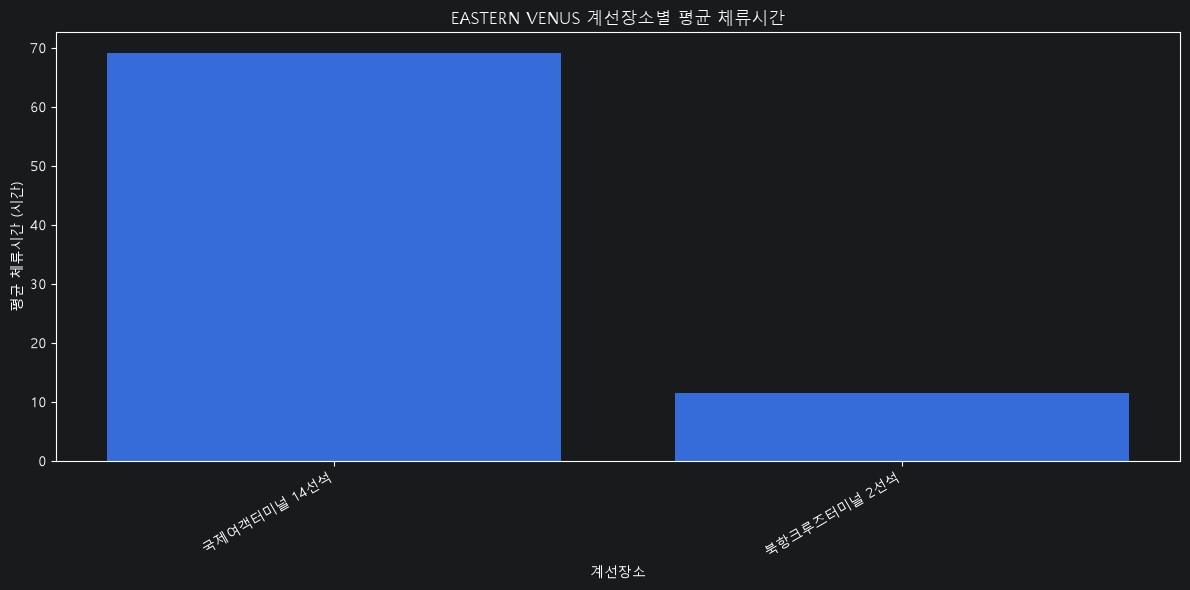

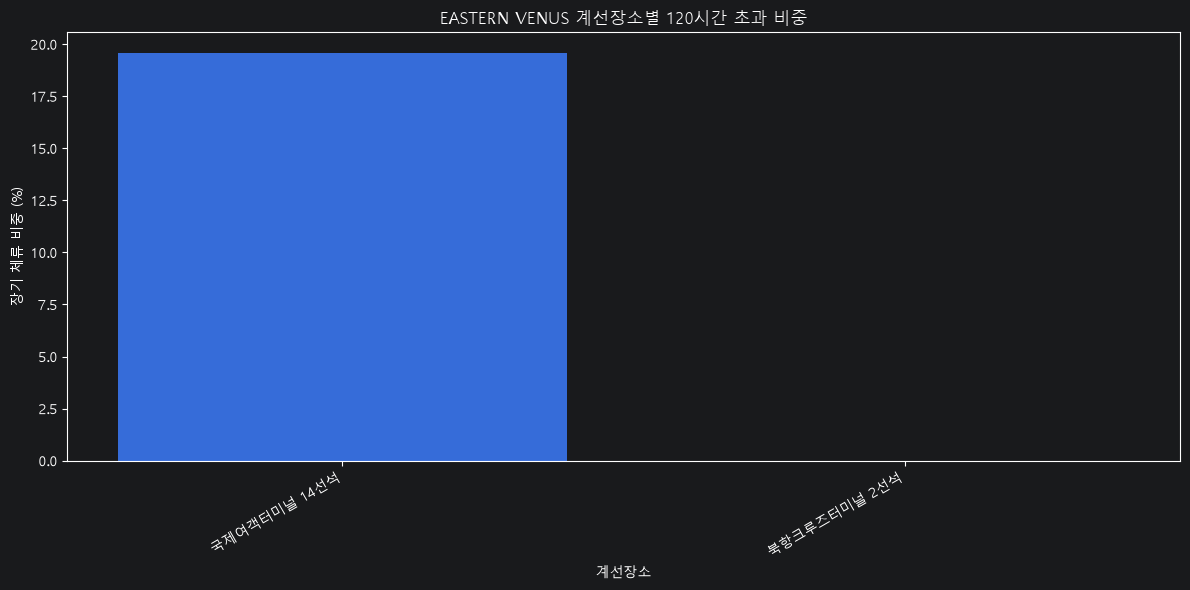

In [82]:


# 1. 계선장소 정리
place_col = "계선장소목록"
stay_col = "체류시간_시간"

place_df = ship_104.copy()

# 장소가 여러 개인 기록 분리
place_df["장소수"] = (
    place_df[place_col]
    .fillna("")
    .apply(lambda x: len([p for p in x.split(" / ") if p.strip()]))
)

single_place = place_df[place_df["장소수"] == 1].copy()
multi_place = place_df[place_df["장소수"] > 1].copy()

print("전체 기록:", len(place_df))
print("단일 장소 기록:", len(single_place))
print("복수 장소 기록:", len(multi_place))

# 2. 단일 장소별 체류시간 통계
place_summary = (
    single_place.groupby(place_col)[stay_col]
    .agg(
        입항건수="count",
        평균체류시간="mean",
        중앙값체류시간="median",
        표준편차="std",
        최대체류시간="max"
    )
    .sort_values("입항건수", ascending=False)
)

# 장기 체류 건수 및 비중 추가
long_stay = (
    single_place.assign(장기체류=single_place[stay_col] > 120)
    .groupby(place_col)["장기체류"]
    .agg(장기체류건수="sum", 장기체류비중_pct=lambda x: x.mean() * 100)
)

place_summary = place_summary.join(long_stay).round(2)

print("\n=== 단일 계선장소별 체류시간 비교 ===")
print(place_summary.to_string())

# 3. 복수 장소 기록은 별도로 확인
print("\n=== 복수 계선장소 기록 ===")
print(
    multi_place[
        ["입항일시", "출항일시", stay_col, place_col]
    ].sort_values("입항일시").to_string(index=False)
)

# 4. 장소별 표본 수와 장기 체류 비중을 시각화
plot_data = place_summary.reset_index()

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.bar(plot_data[place_col], plot_data["평균체류시간"])
plt.ylabel("평균 체류시간 (시간)")
plt.xlabel("계선장소")
plt.title("EASTERN VENUS 계선장소별 평균 체류시간")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
plt.bar(plot_data[place_col], plot_data["장기체류비중_pct"])
plt.ylabel("장기 체류 비중 (%)")
plt.xlabel("계선장소")
plt.title("EASTERN VENUS 계선장소별 120시간 초과 비중")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [83]:
# 120시간 초과 기록의 특성 확인
long_df = ship_104.loc[
    ship_104["체류시간_시간"] > 120
].copy()

long_df["장소수"] = long_df["계선장소목록"].apply(
    lambda x: len([p for p in str(x).split(" / ") if p.strip()])
)

long_df["체류일수"] = long_df["체류시간_시간"] / 24

cols = [
    "입항일시",
    "출항일시",
    "체류시간_시간",
    "체류일수",
    "계선장소목록",
    "전출항지",
    "차항지"
]

print("장기 체류 기록:", len(long_df))
print("\n=== 장기 체류 기록 상세 ===")
print(
    long_df[cols]
    .sort_values("입항일시")
    .to_string(index=False)
)

print("\n=== 장소 유형별 장기 체류 ===")
print(
    long_df.groupby("장소수")["체류시간_시간"]
    .agg(["count", "mean", "median", "max"])
    .rename(index={1: "단일 장소", 2: "복수 장소"})
)

장기 체류 기록: 23

=== 장기 체류 기록 상세 ===
               입항일시                출항일시  체류시간_시간      체류일수                      계선장소목록               전출항지                차항지
2025-03-06 14:00:00 2025-03-15 17:00:00    219.0  9.125000    남외항 N-4박지 / 북항크루즈터미널 2선석                 여수             SASEBO
2025-03-16 08:00:00 2025-04-25 18:00:00    970.0 40.416667 북항크루즈터미널 2선석 / 국제여객터미널 14선석 TSUSHIMA, NAGASAKI     OCEAN DISTRICT
2025-05-11 08:00:00 2025-05-23 17:00:00    297.0 12.375000                국제여객터미널 14선석             SASEBO TSUSHIMA, NAGASAKI
2025-05-24 08:00:00 2025-06-06 18:00:00    322.0 13.416667                국제여객터미널 14선석 TSUSHIMA, NAGASAKI          KAGOSHIMA
2025-06-08 08:00:00 2025-06-13 18:00:00    130.0  5.416667                국제여객터미널 14선석             SASEBO             SASEBO
2025-06-15 09:00:00 2025-06-20 18:00:00    129.0  5.375000                국제여객터미널 14선석             SASEBO           NAGASAKI
2025-06-22 08:00:00 2025-06-27 18:00:00    130.0  5.416667                국제여객터미널 14선석     

In [84]:
# 국제여객터미널 14선석 단일 장소 기록
pier14 = ship_104[
    ship_104["계선장소목록"].eq("국제여객터미널 14선석")
].copy()

pier14 = pier14.sort_values("입항일시").reset_index(drop=True)

pier14["다음입항일시"] = pier14["입항일시"].shift(-1)

pier14["출항후_다음입항까지_시간"] = (
    pier14["다음입항일시"] - pier14["출항일시"]
).dt.total_seconds() / 3600

pier14["체류일수"] = pier14["체류시간_시간"] / 24

# 장기 체류 기록과 다음 입항까지 공백 확인
long_pier14 = pier14[pier14["체류시간_시간"] > 120]

print(
    long_pier14[
        [
            "입항일시",
            "출항일시",
            "체류시간_시간",
            "체류일수",
            "다음입항일시",
            "출항후_다음입항까지_시간",
        ]
    ].to_string(index=False)
)

               입항일시                출항일시  체류시간_시간      체류일수              다음입항일시  출항후_다음입항까지_시간
2025-05-11 08:00:00 2025-05-23 17:00:00    297.0 12.375000 2025-05-24 08:00:00           15.0
2025-05-24 08:00:00 2025-06-06 18:00:00    322.0 13.416667 2025-06-08 08:00:00           38.0
2025-06-08 08:00:00 2025-06-13 18:00:00    130.0  5.416667 2025-06-15 09:00:00           39.0
2025-06-15 09:00:00 2025-06-20 18:00:00    129.0  5.375000 2025-06-22 08:00:00           38.0
2025-06-22 08:00:00 2025-06-27 18:00:00    130.0  5.416667 2025-06-29 08:00:00           38.0
2025-06-29 08:00:00 2025-07-04 18:00:00    130.0  5.416667 2025-07-06 08:00:00           38.0
2025-07-06 08:00:00 2025-07-11 18:00:00    130.0  5.416667 2025-07-13 08:00:00           38.0
2025-09-08 08:00:00 2025-09-13 18:00:00    130.0  5.416667 2025-09-15 08:00:00           38.0
2025-10-12 09:00:00 2025-10-17 18:00:00    129.0  5.375000 2025-10-19 08:00:00           38.0
2025-10-19 08:00:00 2025-10-24 18:00:00    130.0  5.416667 2

In [85]:
# 국제여객터미널 14선석의 입항 간격 분석
pier14 = ship_104[
    ship_104["계선장소목록"].eq("국제여객터미널 14선석")
].copy()

pier14 = pier14.sort_values("입항일시").reset_index(drop=True)

pier14["다음입항일시"] = pier14["입항일시"].shift(-1)

pier14["입항간격_시간"] = (
    pier14["다음입항일시"] - pier14["입항일시"]
).dt.total_seconds() / 3600

# 입항 간격 분포
print("=== 입항 간격 요약 ===")
print(pier14["입항간격_시간"].describe().round(2))

print("\n=== 입항 간격 구간별 건수 ===")
bins = [-float("inf"), 48, 96, 168, 240, float("inf")]
labels = [
    "48시간 이하",
    "48~96시간",
    "96~168시간",
    "168~240시간",
    "240시간 초과"
]

print(
    pd.cut(
        pier14["입항간격_시간"],
        bins=bins,
        labels=labels
    ).value_counts(sort=False)
)

print("\n=== 입항 간격이 240시간을 초과한 사례 ===")
print(
    pier14.loc[
        pier14["입항간격_시간"] > 240,
        ["입항일시", "다음입항일시", "입항간격_시간"]
    ].to_string(index=False)
)

=== 입항 간격 요약 ===
count     96.00
mean     133.51
std      100.21
min       24.00
25%       71.75
50%      130.00
75%      168.00
max      720.00
Name: 입항간격_시간, dtype: float64

=== 입항 간격 구간별 건수 ===
입항간격_시간
48시간 이하      22
48~96시간      12
96~168시간     49
168~240시간     9
240시간 초과      4
Name: count, dtype: int64

=== 입항 간격이 240시간을 초과한 사례 ===
               입항일시              다음입항일시  입항간격_시간
2025-05-11 08:00:00 2025-05-24 08:00:00    312.0
2025-05-24 08:00:00 2025-06-08 08:00:00    360.0
2025-11-30 08:00:00 2025-12-26 08:00:00    624.0
2026-08-30 09:00:00 2026-09-29 09:00:00    720.0
